# Pneumonia Detection from Chest X-Rays: End-to-End ML Pipeline

This notebook presents an end-to-end machine learning pipeline for pneumonia detection from chest X-ray images. It builds a deep learning classifier that predicts whether a chest X-ray is NORMAL or shows signs of PNEUMONIA, extending my earlier COPD detection project from tabular survey data to medical image data within the same healthcare domain, with the aim of supporting early detection of respiratory conditions. The notebook covers the full machine learning cycle: data acquisition from the Kaggle Chest X-Ray Images (Pneumonia) dataset, cleaning and duplicate removal, a stratified train/validation/test split with a held-out batch for retraining, exploratory visualizations with interpretations, and preprocessing with augmentation and class weighting to handle class imbalance. It then trains and compares a baseline convolutional neural network with a MobileNetV2 transfer learning model, evaluates them using accuracy, precision, recall, F1-score, ROC-AUC and a confusion matrix, and provides a single-image prediction function and a retraining function. The best model is saved for deployment through an API and web interface, where users can predict on new X-rays, upload new data and trigger retraining.

**Dataset source:** https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia

## 1. Setup

To import the libraries, fix random seeds so every run gives the same splits and results and mount Google Drive, where the Kaggle dataset is stored.

In [4]:
import os, random, shutil, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid")
print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


## 2. Data Acquisition

### 2.1 Configuration

All paths and key settings live in one place so they can be changed without hunting through the notebook.

- `DRIVE_DATA_DIR`: the Drive folder that holds the downloaded Kaggle dataset.
- `WORK_DIR`: a working copy on Colab's local disk. Reading thousands of small images from Drive is slow, so we copy the data once and train from local disk.
- `NEW_DATA_PER_CLASS`: images per class set aside as the **"new data" batch** that we upload through the UI later to demonstrate retraining.

In [5]:
# Find the folder that directly contains train/ and val/ 
candidates = [p.parent for p in Path("/kaggle/input").rglob("train")
              if p.is_dir() and (p.parent / "val").exists()]
print("Found:", candidates)
DRIVE_DATA_DIR = sorted(candidates, key=lambda p: len(p.parts))[0]

WORK_DIR = Path("/kaggle/working/pneumonia_project")
DATA_DIR = WORK_DIR / "data"
MODELS_DIR = WORK_DIR / "models"
for d in (DATA_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

CLASSES = ["NORMAL", "PNEUMONIA"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NEW_DATA_PER_CLASS = 200     # held back for the retraining
VAL_FRAC, TEST_FRAC = 0.15, 0.15

print("Reading from:", DRIVE_DATA_DIR)
print("Folders found:", [p.name for p in DRIVE_DATA_DIR.iterdir()])

Found: [PosixPath('/kaggle/input/datasets/kamikazikellia/chest-xray-pneumonia/chest_xray'), PosixPath('/kaggle/input/datasets/kamikazikellia/chest-xray-pneumonia/chest_xray/chest_xray')]
Reading from: /kaggle/input/datasets/kamikazikellia/chest-xray-pneumonia/chest_xray
Folders found: ['chest_xray', 'test', 'train', 'val']


### 2.2 Build an inventory of every image

Instead of working with folders directly, we build a **DataFrame with one row per image** (file path, label, original split). Everything later (cleaning, splitting, plotting) becomes simple table operations and the table can be saved as a manifest.

In [6]:
VALID_EXT = {".jpg", ".jpeg", ".png"}
rows = []
for split in ["train", "val", "test"]:
    for label in CLASSES:
        folder = DRIVE_DATA_DIR / split / label
        if not folder.exists():
            print("Missing folder:", folder)
            continue
        for f in folder.iterdir():
            if f.suffix.lower() in VALID_EXT and not f.name.startswith("."):
                rows.append({"path": str(f), "label": label, "orig_split": split})

df = pd.DataFrame(rows)
print("Total images found:", len(df))
display(pd.crosstab(df["orig_split"], df["label"], margins=True))

Total images found: 5856


label,NORMAL,PNEUMONIA,All
orig_split,,,
test,234,390,624
train,1341,3875,5216
val,8,8,16
All,1583,4273,5856


### Interpretation:
- The original download holds roughly **5,800 images**: about 5,200 train, about 620 test, and only **16 in `val`**.
- **PNEUMONIA outnumbers NORMAL by roughly 3 to 1** in the training split.
- The 16-image validation set is far too small to tune a model reliably, so we will **re-split the data ourselves**

## 3. Data Cleaning

### 3.1 Integrity check and image metadata

Before training, we make sure every file is a readable image and record each image's **width, height, colour mode and file size**. This catches corrupt files and the metadata is reused later for visualizations.

In [7]:
def inspect_image(path):
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            w, h = im.size
            return w, h, im.mode, os.path.getsize(path), True
    except Exception:
        return None, None, None, None, False

meta = df["path"].apply(inspect_image)
df[["width", "height", "mode", "file_bytes", "readable"]] = pd.DataFrame(meta.tolist(), index=df.index)

print("Unreadable files:", (~df["readable"]).sum())
print("\nColour modes:")
print(df["mode"].value_counts(dropna=False))
df = df[df["readable"]].copy()
print("\nImages after removing unreadable files:", len(df))

Unreadable files: 0

Colour modes:
mode
L      5573
RGB     283
Name: count, dtype: int64

Images after removing unreadable files: 5856


There are no **Unreadable files**. Any corrupt images are dropped here so they cannot crash training later. X-rays are inherently grayscale, but files may be stored as `L` (grayscale) or `RGB`. Mixed modes are a common cause of shape errors, so in preprocessing we convert everything to **3-channel RGB**

### 3.2 Duplicate detection

Duplicate images are dangerous: if the same X-ray lands in both train and test, the model is "tested" on something it has already seen and the metrics look better than they really are (**data leakage**). We hash each file's bytes (MD5) to find exact duplicates and keep one copy of each.

In [8]:
def file_md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while True:
            block = f.read(chunk)
            if not block:
                break
            h.update(block)
    return h.hexdigest()

df["md5"] = df["path"].apply(file_md5)
dup_mask = df.duplicated(subset="md5", keep="first")
print("Exact duplicate files:", dup_mask.sum())

# Same hash but different labels would be a labelling conflict
conflicts = df.groupby("md5")["label"].nunique()
print("Hashes with conflicting labels:", (conflicts > 1).sum())

df = df[~dup_mask].reset_index(drop=True)
print("Images after de-duplication:", len(df))
display(df["label"].value_counts().to_frame("count"))

Exact duplicate files: 32
Hashes with conflicting labels: 0
Images after de-duplication: 5824


,count
label,
PNEUMONIA,4245
NORMAL,1579


### Interpretation
The duplicate check found 32 exact duplicate files and removed them, leaving 5,824 images. No images shared a hash with a different label (0 conflicting labels), so there are no ambiguous or mislabelled duplicates. The cleaned dataset holds 4,245 PNEUMONIA and 1,579 NORMAL images, a ratio of about 2.7 to 1, so the class imbalance remains. Cleaning removed under 1% of the data which keeps the dataset large enough for transfer learning and protects the evaluation from data leakage.

## 4. Splitting the Data

### 4.1 Hold out a "new data" batch and create train / val / test

Two decisions are made here:

1. **New-data batch for retraining.** We set aside `NEW_DATA_PER_CLASS` images per class (balanced) that the model will never see during initial training. During the demo, we upload these through the UI and trigger retraining, so retraining is shown on genuinely unseen images.
2. **Stratified 70 / 15 / 15 split** of the remaining images. The original `train/val/test` folders are pooled and re-split because the original validation set has only 16 images. **Stratification** keeps the NORMAL:PNEUMONIA ratio the same in each split, and the fixed seed makes it reproducible.

In [9]:
print(df["label"].value_counts())
print(df["orig_split"].value_counts())
print("Total:", len(df))

label
PNEUMONIA    4245
NORMAL       1579
Name: count, dtype: int64
orig_split
train    5190
test      618
val        16
Name: count, dtype: int64
Total: 5824


In [10]:
# balanced new-data batch
new_parts = []
for label in CLASSES:
    sub = df[df["label"] == label]
    new_parts.append(sub.sample(n=NEW_DATA_PER_CLASS, random_state=SEED))
new_df = pd.concat(new_parts)
rest = df.drop(new_df.index)

# stratified train / val / test on the rest
train_df, temp_df = train_test_split(
    rest, test_size=VAL_FRAC + TEST_FRAC, stratify=rest["label"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), stratify=temp_df["label"], random_state=SEED)

new_df = new_df.assign(split="new_data")
train_df = train_df.assign(split="train")
val_df = val_df.assign(split="val")
test_df = test_df.assign(split="test")
full = pd.concat([train_df, val_df, test_df, new_df]).reset_index(drop=True)

display(pd.crosstab(full["split"], full["label"], margins=True))
display(pd.crosstab(full["split"], full["label"], normalize="index").round(3))

label,NORMAL,PNEUMONIA,All
split,,,
new_data,200,200,400
test,207,607,814
train,965,2831,3796
val,207,607,814
All,1579,4245,5824


label,NORMAL,PNEUMONIA
split,,
new_data,0.500,0.500
test,0.254,0.746
train,0.254,0.746
val,0.254,0.746


### Interpretation
The 5,824 cleaned images were split into 3,796 for training (65%), 814 for validation (14%), 814 for testing (14%) and a 400-image new-data batch (7%) held back for the retraining demo. The three main splits have identical class proportions of about 25.4% NORMAL and 74.6% PNEUMONIA, so the stratified split worked and the splits are comparable. The new_data batch is exactly balanced at 200 images per class. It was drawn out first, so the 70/15/15 ratios apply to the remaining 5,424 images.

### 4.2 Copy images into the project folder structure

The files are copied  into `data/<split>/<CLASS>/` on local disk. A manifest CSV records which file went to which split, so the split can be audited.

In [11]:
from tqdm.auto import tqdm

for split in ["train", "val", "test", "new_data"]:
    for label in CLASSES:
        (DATA_DIR / split / label).mkdir(parents=True, exist_ok=True)

for _, r in tqdm(full.iterrows(), total=len(full)):
    src = Path(r["path"])
    dst = DATA_DIR / r["split"] / r["label"] / f"{r['md5'][:10]}_{src.name}"
    if not dst.exists():
        shutil.copy2(src, dst)

full["local_path"] = [str(DATA_DIR / r.split / r.label / f"{r.md5[:10]}_{Path(r.path).name}")
                      for r in full.itertuples()]
full.to_csv(WORK_DIR / "data_manifest.csv", index=False)

for split in ["train", "val", "test", "new_data"]:
    n = sum(len(list((DATA_DIR / split / c).glob("*"))) for c in CLASSES)
    print(f"{split:9s}: {n} files")

  0%|          | 0/5824 [00:00<?, ?it/s]

train    : 3796 files
val      : 814 files
test     : 814 files
new_data : 400 files


## 5. Data Visualization and Interpretation

We look at **four** features: class balance, visual appearance, image dimensions, and pixel intensity (brightness). For each, the question is not just "what does it look like" but **"what does it mean for the model?"**

### 5.1 Feature 1: Class distribution

Class balance decides which metrics are trustworthy. If one class dominates, a model can score high accuracy by simply predicting the majority class. We plot class counts for the full cleaned dataset and for each split.

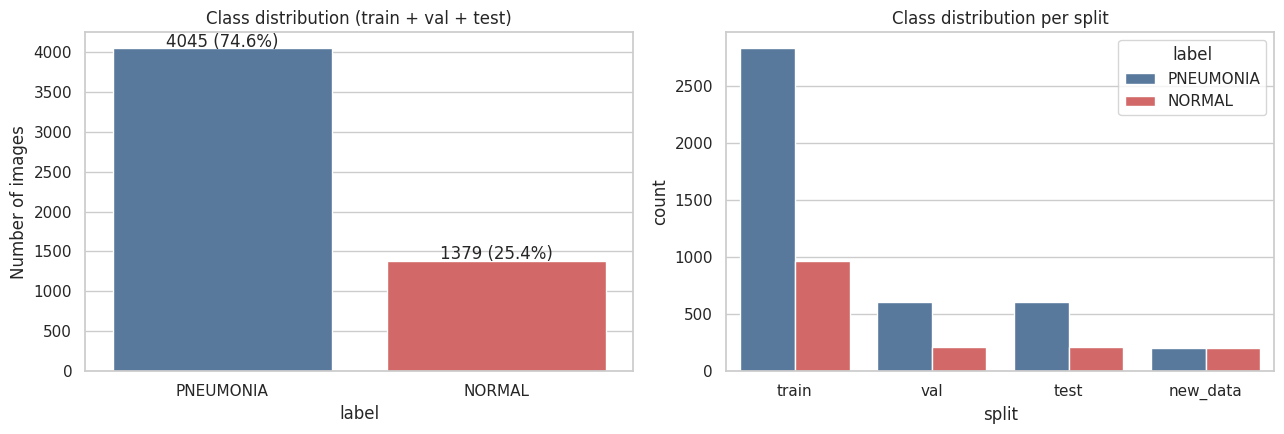

PNEUMONIA : NORMAL ratio = 2.93 : 1


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

counts = full[full["split"] != "new_data"]["label"].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], palette=["#4C78A8", "#E45756"])
axes[0].set_title("Class distribution (train + val + test)")
axes[0].set_ylabel("Number of images")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, f"{v} ({v / counts.sum():.1%})", ha="center")

sns.countplot(data=full, x="split", hue="label", order=["train", "val", "test", "new_data"],
              palette=["#4C78A8", "#E45756"], ax=axes[1])
axes[1].set_title("Class distribution per split")
plt.tight_layout()
plt.show()

ratio = counts["PNEUMONIA"] / counts["NORMAL"]
print(f"PNEUMONIA : NORMAL ratio = {ratio:.2f} : 1")

### Interpretation
The class distribution plot covers the 5,424 images in train, validation and test (the balanced new_data batch is excluded). It shows a clear imbalance: 4,045 PNEUMONIA (74.6%) versus 1,379 NORMAL (25.4%), a ratio of 2.93 : 1. The per-split plot shows the same roughly 3:1 shape in train, validation and test, so the stratified split worked, while new_data is balanced at 200 images per class. Because of this imbalance, a model that predicts PNEUMONIA for every image would score about 75% accuracy without detecting a single healthy patient. So the project uses class weights and judges the models on precision, recall, F1, ROC-AUC and the confusion matrix, with recall on PNEUMONIA as the priority metric

### 5.2 Feature 2: What the images actually look like

Plotting samples shows what the model has to learn. We display random images from each class in a grid, using a fixed seed so the grid is reproducible.

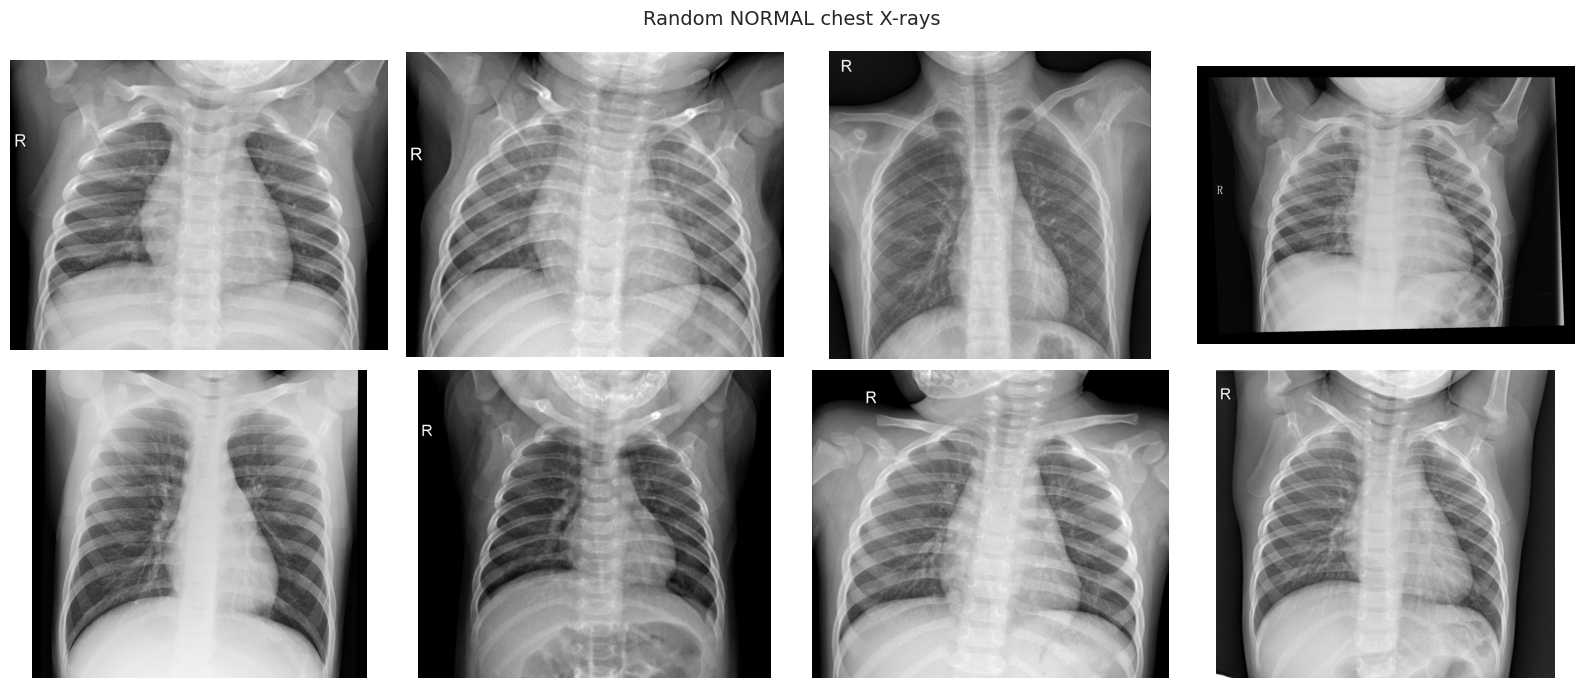

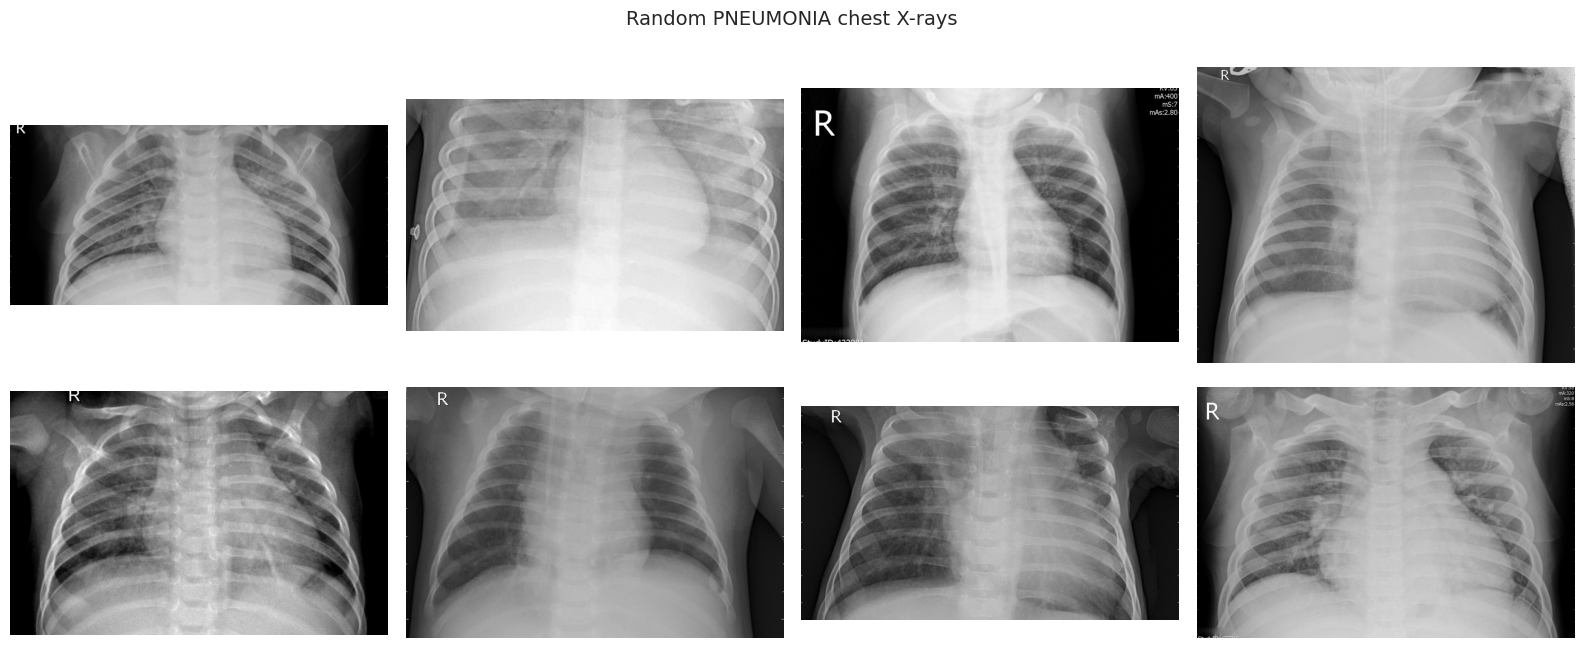

In [13]:
def show_samples(label, n=8, seed=SEED):
    sub = full[(full["split"] == "train") & (full["label"] == label)].sample(n, random_state=seed)
    fig, axes = plt.subplots(2, n // 2, figsize=(16, 7))
    for ax, p in zip(axes.ravel(), sub["local_path"]):
        ax.imshow(Image.open(p).convert("L"), cmap="gray")
        ax.axis("off")
    fig.suptitle(f"Random {label} chest X-rays", fontsize=14)
    plt.tight_layout()
    plt.show()

show_samples("NORMAL")
show_samples("PNEUMONIA")

### After the cell: interpretation
In the sample grid, NORMAL X-rays show dark, clear lung fields with sharp rib outlines and well-defined heart and diaphragm borders. Most PNEUMONIA X-rays look hazier, with greyer lung fields, less distinct ribs and patchy whitish areas, although a couple (bottom row) look almost as clear as normal ones, which shows why the task is hard. The two classes also differ in how the images look. NORMAL images tend to be larger, wider frames showing more of the neck and shoulders, and the chests look bigger, while many PNEUMONIA images are tighter crops of smaller chests, and one is a very wide, thin strip. Three of the eight PNEUMONIA images contain monitoring leads, wires or devices, a timestamp appears on one, and letter markers (“R”) appear in both classes. No obvious leads or devices are visible in the NORMAL sample. A model could latch onto these non-medical cues (image framing, patient size, equipment) instead of real lung pathology, which is why augmentation is used and why very high accuracy needs careful interpretation.

### 5.3 Feature 3: Image dimensions

#### Before the cell
Images come from different machines and hospitals and have **different resolutions**. We plot width and height per class. Systematic size differences between classes could let a model "cheat" by recognising size rather than disease. It also tells us what to resize to.

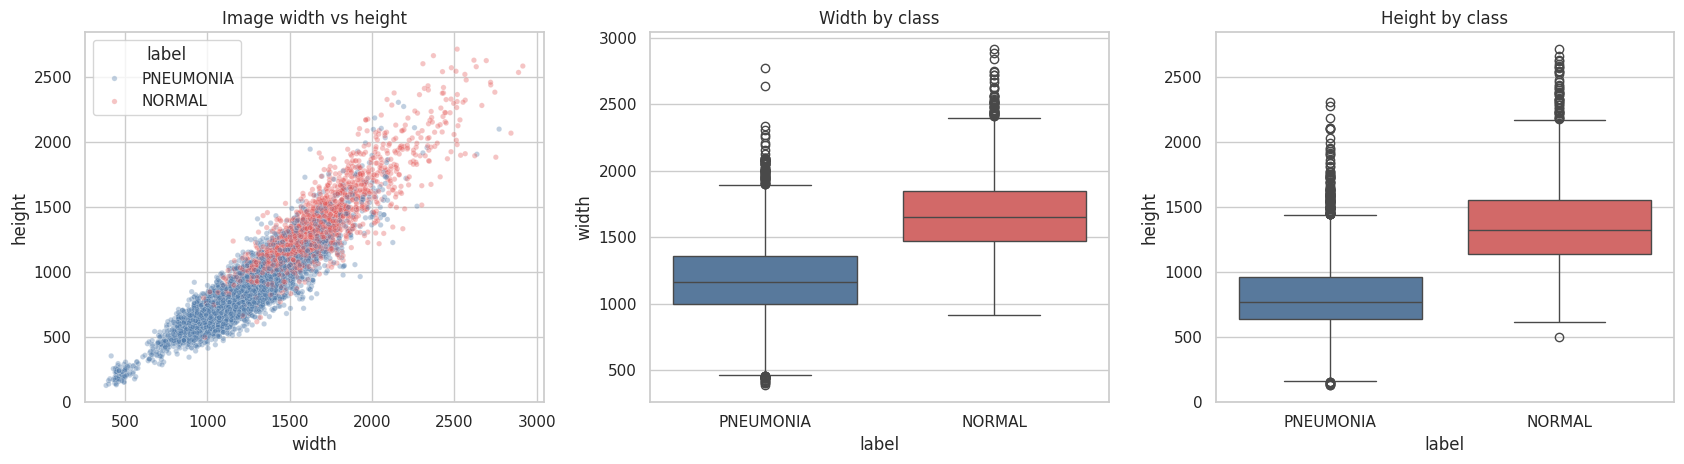

label         NORMAL  PNEUMONIA
width  count  1579.0     4245.0
       mean   1686.0     1194.0
       std     304.0      285.0
       min     912.0      384.0
       25%    1472.0     1000.0
       50%    1654.0     1160.0
       75%    1848.0     1360.0
       max    2916.0     2772.0
height count  1579.0     4245.0
       mean   1378.0      818.0
       std     341.0      271.0
       min     496.0      127.0
       25%    1140.0      640.0
       50%    1323.0      768.0
       75%    1554.0      960.0
       max    2713.0     2304.0

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.scatterplot(data=full, x="width", y="height", hue="label", alpha=0.35, s=15,
                palette=["#4C78A8", "#E45756"], ax=axes[0])
axes[0].set_title("Image width vs height")

sns.boxplot(data=full, x="label", y="width", palette=["#4C78A8", "#E45756"], ax=axes[1])
axes[1].set_title("Width by class")

sns.boxplot(data=full, x="label", y="height", palette=["#4C78A8", "#E45756"], ax=axes[2])
axes[2].set_title("Height by class")
plt.tight_layout()
plt.show()

display(full.groupby("label")[["width", "height"]].describe().round(0).T)

### Interpretation
The two classes differ clearly in size. NORMAL images are much larger, with a median width of 1,654 px and median height of 1,323 px, against 1,160 px and 768 px for PNEUMONIA. The boxplots show that the middle 50% of the two classes don’t overlap at all, in width (1,472 to 1,848 px for NORMAL, 1,000 to 1,360 px for PNEUMONIA) or in height (1,140 to 1,554 px against 640 to 960 px). In the scatter plot the classes overlap only in a band of mid-sized images, and PNEUMONIA extends down to very small images (minimum 384 px wide and 127 px tall) while NORMAL starts at 912 px wide. Image size alone could therefore separate many cases, which makes it a likely dataset bias, and a high test score has to be read with that in mind.

### 5.4 Feature 4: Pixel intensity (brightness)

Pneumonia shows up as **whiter regions** in the lungs, so average brightness is a natural feature to compare between classes. We compute the mean pixel value of each image (after resizing to 224 x 224 grayscale for speed) on a sample of the training set, then plot its distribution per class, and also plot the **average image** of each class to see where the differences are located.

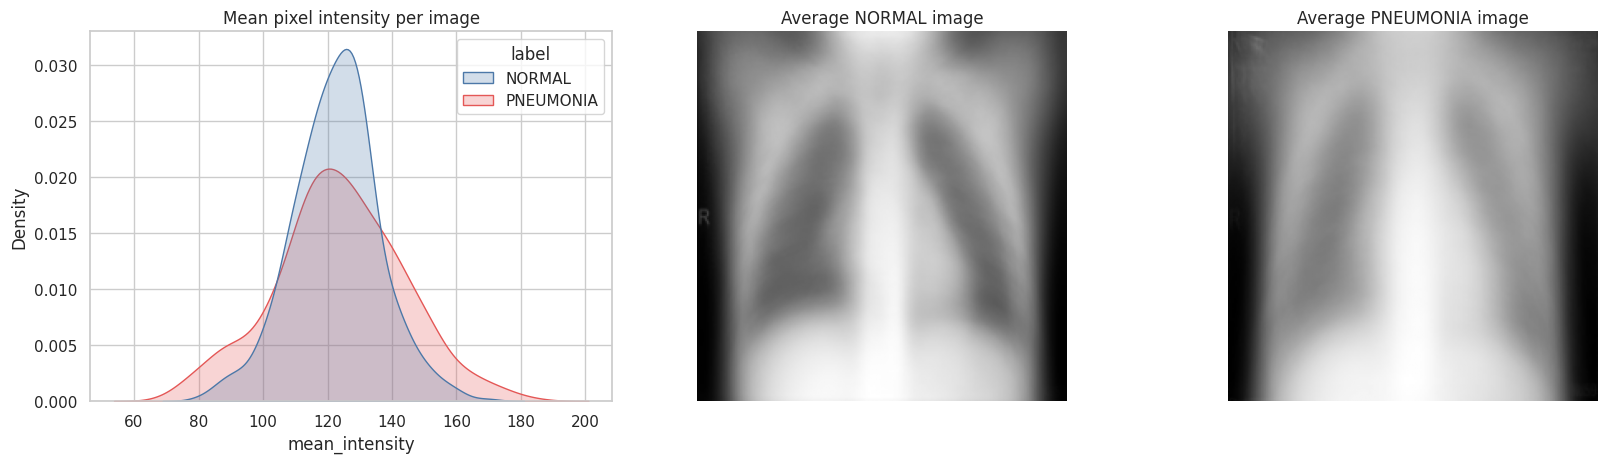

           count   mean   std   min    25%    50%    75%    max
label                                                          
NORMAL     600.0  122.5  13.4  80.1  114.2  122.9  130.4  169.7
PNEUMONIA  600.0  123.6  20.0  70.5  112.1  123.2  136.9  184.2


In [15]:
sample = (full[full["split"] == "train"]
          .groupby("label", group_keys=False)
          .apply(lambda g: g.sample(min(len(g), 600), random_state=SEED)))

def load_gray(p):
    return np.asarray(Image.open(p).convert("L").resize(IMG_SIZE), dtype=np.float32)

arrays = {lab: np.stack([load_gray(p) for p in sample[sample.label == lab]["local_path"]])
          for lab in CLASSES}

intensity = pd.DataFrame({
    "label": np.repeat(CLASSES, [len(arrays[c]) for c in CLASSES]),
    "mean_intensity": np.concatenate([arrays[c].mean(axis=(1, 2)) for c in CLASSES]),
})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.kdeplot(data=intensity, x="mean_intensity", hue="label", fill=True,
            palette=["#4C78A8", "#E45756"], common_norm=False, ax=axes[0])
axes[0].set_title("Mean pixel intensity per image")
for ax, lab in zip(axes[1:], CLASSES):
    ax.imshow(arrays[lab].mean(axis=0), cmap="gray")
    ax.set_title(f"Average {lab} image")
    ax.axis("off")
plt.tight_layout()
plt.show()

print(intensity.groupby("label")["mean_intensity"].describe().round(1))

### Interpretation
Average brightness is virtually identical between the two classes (about 122 for both), so overall brightness is not a usable signal for telling them apart. The difference is in spread: PNEUMONIA images vary much more (standard deviation 20.0 vs 13.9, range 67 to 185 vs 73 to 170), probably because lung opacities make some scans much brighter or darker, and the two distributions overlap heavily, so a CNN has to learn spatial patterns, not overall brightness. The average images show where the classes differ: the NORMAL average has dark, well-defined lung fields against a bright central column, while the PNEUMONIA average is hazier, with greyer lung fields and lower contrast. Brightness and contrast also depend on scanner settings and exposure, and a faint “R” marker is visible in the NORMAL average, so a model could pick up non-medical cues, which is why brightness and contrast augmentation is used to reduce this risk.

### 5.5 Summary of what the exploration tells us

| Feature | Finding | Decision for modelling |
|---|---|---|
| Class balance | PNEUMONIA is about 3x NORMAL | Class weights, report recall / F1 / AUC, not just accuracy |
| Appearance | Pneumonia shows cloudy opacities, but cases overlap | Use a CNN with transfer learning, augmentation |
| Dimensions | Widely varying sizes, possible class-size bias | Resize all images to 224 x 224 identically in training and API |
| Brightness | Pneumonia tends to be brighter, with heavy overlap | Brightness/contrast augmentation to avoid shortcut learning |

## 6. Preprocessing Pipeline

### 6.1 Load the datasets with `tf.data`

We build input pipelines that read the images from `data/train`, `data/val` and `data/test`, resize them to 224 x 224 and batch them.


In [17]:
common = dict(
    labels="inferred",
    label_mode="binary",
    class_names=CLASSES,
    color_mode="rgb",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED,
)

train_ds = tf.keras.utils.image_dataset_from_directory(DATA_DIR / "train", shuffle=True, **common)
val_ds   = tf.keras.utils.image_dataset_from_directory(DATA_DIR / "val",   shuffle=False, **common)
test_ds  = tf.keras.utils.image_dataset_from_directory(DATA_DIR / "test",  shuffle=False, **common)

print("Class order:", train_ds.class_names)
for images, labels in train_ds.take(1):
    print("Batch images:", images.shape, "| dtype:", images.dtype,
          "| pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))
    print("Batch labels:", labels.shape)

Found 3796 files belonging to 2 classes.
Found 814 files belonging to 2 classes.
Found 814 files belonging to 2 classes.
Class order: ['NORMAL', 'PNEUMONIA']
Batch images: (32, 224, 224, 3) | dtype: <dtype: 'float32'> | pixel range: 0.0 to 255.0
Batch labels: (32, 1)


### 6.2 Class weights

To compensate for the imbalance without throwing images away, we compute **class weights**. The minority class (NORMAL) gets a larger weight, so mistakes on it cost more during training.

In [18]:
train_labels = full[full["split"] == "train"]["label"].map({"NORMAL": 0, "PNEUMONIA": 1}).values
weights = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=train_labels)
class_weight = {0: float(weights[0]), 1: float(weights[1])}
print("Class weights:", class_weight)

Class weights: {0: 1.966839378238342, 1: 0.6704344754503709}


### Interpretation
Class weights were computed with the “balanced” method from the training labels, giving NORMAL a weight of 1.97 and PNEUMONIA 0.67. This makes a mistake on a NORMAL image count about three times as much as one on a PNEUMONIA image, which offsets the 3:1 imbalance without discarding any data. These weights are passed to model.fit() so the model cannot score well by predicting PNEUMONIA for everything.

### 6.3 Data augmentation

Augmentation creates slightly altered copies of training images on the fly, which reduces overfitting and makes the model robust to differences in positioning and exposure.

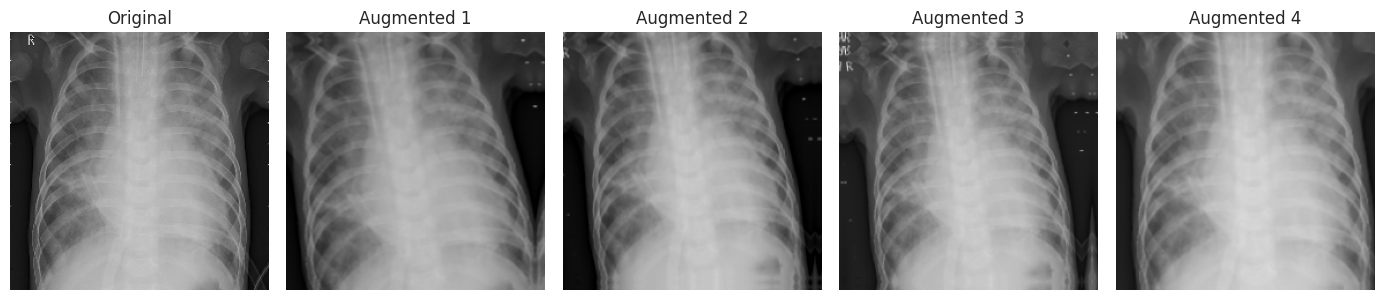

In [26]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomBrightness(0.10, value_range=(0, 255)),
    tf.keras.layers.RandomContrast(0.10),
], name="data_augmentation")

# Visual check: the same training image augmented several times
for images, labels in train_ds.take(1):
    img = images[0]
    plt.figure(figsize=(14, 3.5))
    plt.subplot(1, 5, 1)
    plt.imshow(tf.cast(img, tf.uint8)); plt.title("Original"); plt.axis("off")
    for i in range(4):
        aug = data_augmentation(tf.expand_dims(img, 0), training=True)[0]
        plt.subplot(1, 5, i + 2)
        plt.imshow(tf.cast(tf.clip_by_value(aug, 0, 255), tf.uint8))
        plt.title(f"Augmented {i + 1}"); plt.axis("off")
    plt.tight_layout(); plt.show()

### Interpretation
The four augmented versions are still recognizable as the same chest X-ray, with small shifts, slight rotation and zoom, and changes in brightness and contrast. The ribs, spine and lung fields stay anatomically plausible, so the settings are safe to keep. The only side effect is at the edges, where shifted or rotated images are filled by reflecting nearby pixels, which leaves faint mirrored strips on some copies (for example augmented 1 and 4). This is minor at these strengths, but it is the reason not to increase the rotation, zoom or shift further.

### 6.4 Performance: cache and prefetch

`cache()` keeps decoded images in memory after the first epoch and `prefetch()` prepares the next batch while the GPU or CPU is busy with the current one. Together they remove the data-loading bottleneck and speed up training and retraining.

In [25]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)
print("Input pipelines ready.")

Input pipelines ready.


# PART 2: Modelling, Evaluation, Prediction and Retraining

**This part builds** the model, model testing, saves the model and it's metadata, contains the single image prediction function and retraining trigger and function.


## 8. Model 1: Baseline CNN (trained from scratch)

### 8.1 Shared helpers

We define the pieces both models share:

- `augment_ds()` applies the augmentation from Section 6.3 to a dataset **in the data pipeline**, with a fresh random transformation every epoch. This is a change from what Section 6.3 said (augmentation inside the model). Putting random layers inside the model made the `.h5` file unreliable: Keras could not save some of them (`RandomBrightness`), and a model reloaded from `.h5` could not be saved again, which breaks retraining. Applying augmentation in the pipeline gives the same training effect, and the saved model is a clean **inference-only** network (smaller, faster, and safe to reload and retrain).
- `get_metrics()` returns the metrics tracked during training: accuracy, precision, recall and AUC. Because of the class imbalance, recall and AUC matter more than accuracy.
- `get_callbacks()` adds **early stopping** (stop when validation loss stops improving and restore the best weights) and **learning-rate reduction** (cut the learning rate when progress stalls).
- `plot_history()` draws loss, accuracy and AUC curves for training vs validation, which is the main way to spot overfitting.

In [22]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)
import json, datetime

print("GPU available:", tf.config.list_physical_devices("GPU"))

INPUT_SHAPE = IMG_SIZE + (3,)
L = tf.keras.layers

def augment_ds(ds):
    # data_augmentation is the Sequential block defined in Section 6.3
    return ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                  num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

def get_metrics():
    return [
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ]

def get_callbacks(patience=4):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                         restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                             patience=2, min_lr=1e-7, verbose=1),
    ]

def merge_histories(*histories):
    out = {}
    for h in histories:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

def plot_history(h, title, finetune_start=None):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for ax, metric in zip(axes, ["loss", "accuracy", "auc"]):
        ax.plot(h[metric], label="train")
        ax.plot(h["val_" + metric], label="validation")
        if finetune_start is not None:
            ax.axvline(finetune_start - 0.5, color="gray", ls="--", label="fine-tuning starts")
        ax.set_title(metric)
        ax.set_xlabel("epoch")
        ax.legend()
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 8.2 Experiment tracking: TensorBoard and Weights & Biases
Keras does not keep a record of training runs: the `History` object lives only in memory and disappears when the Kaggle session ends. We therefore log every run to two tools:

- **TensorBoard** writes logs to a local `logs/` folder (`pneumonia_project/logs`), which is kept when the notebook version is saved. The inline TensorBoard viewer does not work in Kaggle, so the logs can be downloaded and viewed on a local computer with `tensorboard --logdir logs`.
- **Weights & Biases (W&B)** stores each run online, so runs can be compared across sessions. We log the training curves (every epoch), the evaluation results, the saved model as a versioned artifact, and the retraining runs.

**Login without typing a key:** the W&B API key is read from **Kaggle Secrets** (*Add-ons > Secrets*). Add a secret with the label `WANDB_API_KEY`, paste your key from wandb.ai/authorize, and make sure it is attached to this notebook and that **Internet** is switched on in the session settings. The key never appears in the notebook. If the login fails, the notebook falls back to **offline mode** (runs are saved locally and can be uploaded later with `wandb sync`), so training still works.

In [27]:
import subprocess, sys
try:
    import wandb
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wandb"], check=True)
    import wandb
from wandb.integration.keras import WandbMetricsLogger

WANDB_PROJECT = "pneumonia-xray"
LOGS_DIR = WORK_DIR / "logs"
LOGS_DIR.mkdir(parents=True, exist_ok=True)

try:
    os.environ.pop("WANDB_MODE", None)         
    from kaggle_secrets import UserSecretsClient
    os.environ["WANDB_API_KEY"] = UserSecretsClient().get_secret("WANDB_API_KEY")
    wandb.login(verify=True)                  
    print("W&B: logged in using Kaggle Secrets.")
except Exception as e:
    os.environ["WANDB_MODE"] = "offline"
    print(f"W&B: login failed ({type(e).__name__}: {e}); running OFFLINE. Runs are stored locally.")

def wb_start(name, config=None, tags=None):
    return wandb.init(project=WANDB_PROJECT, name=name, config=config or {},
                      tags=tags or [], reinit="finish_previous")

def tracking_callbacks(name):
    tb_dir = LOGS_DIR / name
    tb_dir.mkdir(parents=True, exist_ok=True)
    return [tf.keras.callbacks.TensorBoard(log_dir=str(tb_dir)), WandbMetricsLogger()]

print("Project:", WANDB_PROJECT, "| TensorBoard logs:", LOGS_DIR)
print("W&B mode:", os.environ.get("WANDB_MODE", "online"))

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: k-kamikazi (k-kamikazi-african-leadership-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B: logged in using Kaggle Secrets.
Project: pneumonia-xray | TensorBoard logs: /kaggle/working/pneumonia_project/logs
W&B mode: online


### 8.3 Build the baseline CNN

The baseline is a small convolutional network trained **from scratch**. It gives us a reference point for judging whether the extra complexity of a pretrained model is worthwhile.

Architecture:
- `Rescaling(1/255)` to bring pixels into 0 to 1 (scaling is part of the model, so the API does not need its own scaling code). Augmentation is not part of the model; it is applied to the training data (Section 8.4).
- Four blocks of `Conv2D` (32, 64, 128, 128 filters) + `BatchNormalization` + `MaxPooling2D`. Early layers pick up edges and textures, deeper layers combine them into larger lung patterns.
- `GlobalAveragePooling2D`, then `Dropout` (0.4), a small dense layer of 64 units, a second `Dropout` (0.3), and **one sigmoid unit** that outputs the probability of PNEUMONIA. The two dropout layers act as regularization.

In [28]:
def build_baseline_cnn():
    inputs = tf.keras.Input(shape=INPUT_SHAPE)
    x = L.Rescaling(1.0 / 255)(inputs)
    for filters in (32, 64, 128, 128):
        x = L.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = L.BatchNormalization()(x)
        x = L.MaxPooling2D()(x)
    x = L.GlobalAveragePooling2D()(x)
    x = L.Dropout(0.4)(x)
    x = L.Dense(64, activation="relu")(x)
    x = L.Dropout(0.3)(x)
    outputs = L.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(inputs, outputs, name="baseline_cnn")

tf.keras.utils.set_random_seed(SEED)
baseline_model = build_baseline_cnn()
baseline_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                       loss="binary_crossentropy", metrics=get_metrics())
baseline_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 250,561 (978.75 KB)

 Trainable params: 249,857 (976.00 KB)

 Non-trainable params: 704 (2.75 KB)

### Interpretation
The baseline has **250,561 parameters** (about 1 MB), of which 249,857 are trainable. The other 704 are the BatchNormalization moving averages, which are updated during training but not by gradient descent. This is small by deep learning standards, so training and later retraining are quick. The last layer outputs `(None, 1)`, a single probability of PNEUMONIA per image which is the format the evaluation code and the API expect.

### 8.4 Train the baseline

We train on the **augmented** training data (`train_aug`) with `class_weight` (from Section 6.2) so mistakes on the minority NORMAL class cost more, and use early stopping so we do not have to guess the number of epochs. Validation data is used only to monitor progress and for early stopping, never for the final test numbers.

Epoch 1/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 21s 168ms/step - accuracy: 0.9336 - auc: 0.9796 - loss: 0.1765 - precision: 0.9788 - recall: 0.9311 - val_accuracy: 0.4607 - val_auc: 0.9555 - val_loss: 1.6906 - val_precision: 0.9941 - val_recall: 0.2784 - learning_rate: 2.7000e-05
Epoch 2/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 21s 169ms/step - accuracy: 0.9410 - auc: 0.9841 - loss: 0.1591 - precision: 0.9826 - recall: 0.9375 - val_accuracy: 0.4226 - val_auc: 0.9358 - val_loss: 1.9938 - val_precision: 0.9928 - val_recall: 0.2273 - learning_rate: 2.7000e-05
Epoch 3/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 21s 167ms/step - accuracy: 0.9405 - auc: 0.9819 - loss: 0.1695 - precision: 0.9812 - recall: 0.9382 - val_accuracy: 0.8563 - val_auc: 0.9884 - val_loss: 0.3351 - val_precision: 0.9960 - val_recall: 0.8105 - learning_rate: 2.7000e-05
Epoch 4/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 21s 169ms/step - accuracy: 0.9405 - auc: 0.9844 - loss: 0.1577 - precision: 0.9815 - recall: 0.9378 - val_accuracy: 0.5086 - val_auc: 0.9612 

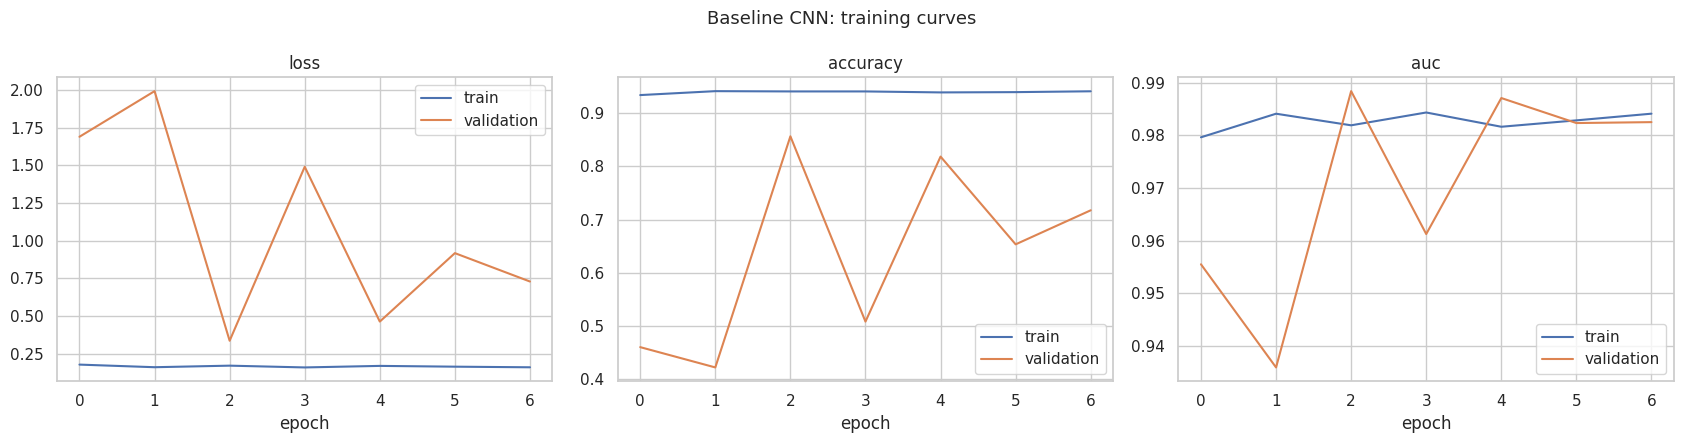

epoch/accuracy,▁███▆▆█
epoch/auc,▁█▄█▄▆█
epoch/epoch,▁▂▃▅▆▇█
epoch/learning_rate,████▃▃▁
epoch/loss,█▂▅▁▅▃▁
epoch/precision,▁█▅▆▂▇▁
epoch/recall,▁▆▆▆▆▄█
epoch/val_accuracy,▂▁█▂▇▅▆
epoch/val_auc,▄▁█▄█▇▇
epoch/val_loss,▇█▁▆▂▃▃
+2,...


In [30]:
EPOCHS_BASELINE = 20
train_aug = augment_ds(train_ds)      # fresh random augmentation every epoch

wb_start("baseline-cnn", tags=["baseline"], config={
    "model": "baseline_cnn", "img_size": list(IMG_SIZE), "batch_size": BATCH_SIZE,
    "learning_rate": 1e-3, "max_epochs": EPOCHS_BASELINE, "class_weight": class_weight,
    "n_train_images": int(len(full[full["split"] == "train"])), "seed": SEED})

history_baseline = baseline_model.fit(
    train_aug,
    validation_data=val_ds,
    epochs=EPOCHS_BASELINE,
    class_weight=class_weight,
    callbacks=get_callbacks(patience=4) + tracking_callbacks("baseline_cnn"),
)
hist_baseline = merge_histories(history_baseline)
plot_history(hist_baseline, "Baseline CNN: training curves")
wandb.finish()

### Interpretation
Training ran for 7 epochs and stopped when validation loss had not improved for 4 epochs. Early stopping restored the weights from **epoch 3** (plotted as epoch 2), the best epoch, with validation loss 0.335, validation accuracy 85.6% and validation AUC 0.988.

The training curves are almost flat (accuracy about 94%, loss about 0.16, AUC about 0.98 in every epoch), while the validation curves swing widely: validation accuracy jumps between 42% and 86% and validation loss between 0.34 and 1.99. Validation precision stays above 99% in every epoch while validation recall moves between 23% and 81%, so the instability comes from the model calling many PNEUMONIA images NORMAL, not from false alarms. Validation AUC stays high throughout (0.94 to 0.99), which means the model ranks the images well but its probabilities are poorly placed around the 0.5 cut-off. A likely cause is the BatchNormalization layers: at inference they use running statistics that had not settled to match the batch statistics seen in training. This is instability rather than classic overfitting, since training loss is not falling while validation loss rises. The best validation AUC of **0.988** is the reference point the transfer-learning model has to beat.

## 9. Model 2: MobileNetV2 Transfer Learning

### 9.1 Why transfer learning here
MobileNetV2 was pretrained on ImageNet (millions of everyday photos). Even though X-rays look nothing like cats and cars, the early layers have already learned general visual building blocks (edges, textures, shapes), so we reuse them and only train a small classifier on top. This usually works much better than training from scratch on a few thousand images.

We train in **two stages**:
1. **Feature extraction:** freeze the pretrained base and train only the new classification head.
2. **Fine-tuning:** unfreeze the last part of the base and train it with a very small learning rate so it adapts to X-rays without destroying what it already knows.

### 9.2 Build the model

- Input scaling: MobileNetV2 expects pixels in **[-1, 1]**, so `Rescaling(1/127.5, offset=-1)` is used instead of 1/255. It is a normal layer, so it is saved inside the model file.
- `base(x, training=False)` keeps the base's BatchNormalization layers in inference mode, which is important when the base is frozen or only partly unfrozen.
- Head: global average pooling, dropout, and one sigmoid unit (probability of PNEUMONIA), the same output as the baseline so the two are directly comparable.

In [35]:
def build_mobilenet():
    base = tf.keras.applications.MobileNetV2(
        input_shape=INPUT_SHAPE, include_top=False, weights="imagenet")
    base.trainable = False
    inputs = tf.keras.Input(shape=INPUT_SHAPE)
    x = L.Rescaling(1.0 / 127.5, offset=-1)(inputs)
    x = base(x, training=False)
    x = L.GlobalAveragePooling2D()(x)
    x = L.Dropout(0.3)(x)
    outputs = L.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(inputs, outputs, name="mobilenetv2_transfer"), base

def set_finetune_policy(model, n_last=30):
    # Unfreeze the last n_last layers of the pretrained base; keep BatchNorm layers frozen.
    bases = [l for l in model.layers if isinstance(l, tf.keras.Model)]
    if not bases:
        return model
    base = bases[0]
    base.trainable = True
    for layer in base.layers[:-n_last]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, L.BatchNormalization):
            layer.trainable = False
    return model

tf.keras.utils.set_random_seed(SEED)
mobilenet_model, mobilenet_base = build_mobilenet()
mobilenet_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                        loss="binary_crossentropy", metrics=get_metrics())
trainable = sum(int(np.prod(w.shape)) for w in mobilenet_model.trainable_weights)
total = mobilenet_model.count_params()
print(f"Trainable parameters (stage 1): {trainable:,} of {total:,}")

Trainable parameters (stage 1): 1,281 of 2,259,265


### Interpretation
Only **1,281 of 2,259,265 parameters** (the new sigmoid head) are trainable in stage 1, while the pretrained MobileNetV2 base (about 2.26 million parameters) is frozen. This is why stage 1 is fast and hard to overfit.

### 9.3 Stage 1: train the classification head

The base is frozen and only the new head is trained, with a normal learning rate (1e-3).

In [36]:
wb_start("mobilenetv2", tags=["transfer-learning"], config={
    "model": "mobilenetv2_transfer", "pretrained_weights": "imagenet",
    "img_size": list(IMG_SIZE), "batch_size": BATCH_SIZE, "head_learning_rate": 1e-3,
    "class_weight": class_weight, "n_train_images": int(len(full[full["split"] == "train"])),
    "seed": SEED})

history_head = mobilenet_model.fit(
    train_aug,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight,
    callbacks=get_callbacks(patience=3) + tracking_callbacks("mobilenetv2"),
)

Epoch 1/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 249ms/step - accuracy: 0.7737 - auc: 0.8671 - loss: 0.4543 - precision: 0.9119 - recall: 0.7711 - val_accuracy: 0.9177 - val_auc: 0.9730 - val_loss: 0.2269 - val_precision: 0.9128 - val_recall: 0.9835 - learning_rate: 0.0010
Epoch 2/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 20s 167ms/step - accuracy: 0.8973 - auc: 0.9642 - loss: 0.2568 - precision: 0.9664 - recall: 0.8933 - val_accuracy: 0.9423 - val_auc: 0.9771 - val_loss: 0.1782 - val_precision: 0.9531 - val_recall: 0.9703 - learning_rate: 0.0010
Epoch 3/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 20s 167ms/step - accuracy: 0.9004 - auc: 0.9700 - loss: 0.2293 - precision: 0.9708 - recall: 0.8933 - val_accuracy: 0.9459 - val_auc: 0.9787 - val_loss: 0.1650 - val_precision: 0.9622 - val_recall: 0.9654 - learning_rate: 0.0010
Epoch 4/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 20s 166ms/step - accuracy: 0.9141 - auc: 0.9750 - loss: 0.2067 - precision: 0.9739 - recall: 0.9092 - val_accuracy: 0.9398 - val_auc: 0.9796 - val_loss: 

### Interpretation
Validation AUC was already 0.973 after the first epoch and rose to about 0.980 by epoch 4, after which it levelled off between 0.979 and 0.981. Validation loss fell from 0.227 to about 0.154 and then flattened, and ReduceLROnPlateau cut the learning rate at epochs 8 and 10 as progress stalled. Validation accuracy (about 94%) was higher than training accuracy (about 92 to 93%) throughout stage 1. This is expected, because dropout and augmentation are active only during training, so the training numbers are measured on harder inputs. With the base frozen, the model already beats the baseline's best validation accuracy (94% against 86%) and is far more stable from epoch to epoch, so fine-tuning here is polish on top of a strong result rather than the main source of improvement.

### 9.4 Stage 2: fine-tune the top of the base

We unfreeze the last 30 layers of MobileNetV2 (keeping BatchNorm layers frozen for stability) and **recompile with a 100x smaller learning rate (1e-5)**. Recompiling is required for the new `trainable` flags to take effect. A small learning rate is critical: large updates would wipe out the pretrained features.

Trainable parameters (stage 2): 1,512,001
Epoch 11/20


E0000 00:00:1795521574.911816     261 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


 21/119 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.9274 - auc: 0.9827 - loss: 0.1748 - precision: 0.9746 - recall: 0.9242

E0000 00:00:1795521584.073574     260 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


119/119 ━━━━━━━━━━━━━━━━━━━━ 41s 243ms/step - accuracy: 0.9328 - auc: 0.9809 - loss: 0.1751 - precision: 0.9781 - recall: 0.9308 - val_accuracy: 0.9533 - val_auc: 0.9829 - val_loss: 0.1417 - val_precision: 0.9718 - val_recall: 0.9654 - learning_rate: 1.0000e-05
Epoch 12/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 20s 165ms/step - accuracy: 0.9334 - auc: 0.9829 - loss: 0.1647 - precision: 0.9778 - recall: 0.9318 - val_accuracy: 0.9509 - val_auc: 0.9849 - val_loss: 0.1363 - val_precision: 0.9733 - val_recall: 0.9605 - learning_rate: 1.0000e-05
Epoch 13/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 20s 166ms/step - accuracy: 0.9447 - auc: 0.9871 - loss: 0.1425 - precision: 0.9823 - recall: 0.9428 - val_accuracy: 0.9251 - val_auc: 0.9863 - val_loss: 0.1871 - val_precision: 0.9875 - val_recall: 0.9110 - learning_rate: 1.0000e-05
Epoch 14/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 20s 165ms/step - accuracy: 0.9436 - auc: 0.9884 - loss: 0.1381 - precision: 0.9802 - recall: 0.9435 - val_accuracy: 0.9582 - val_auc: 0.9874 - val_lo

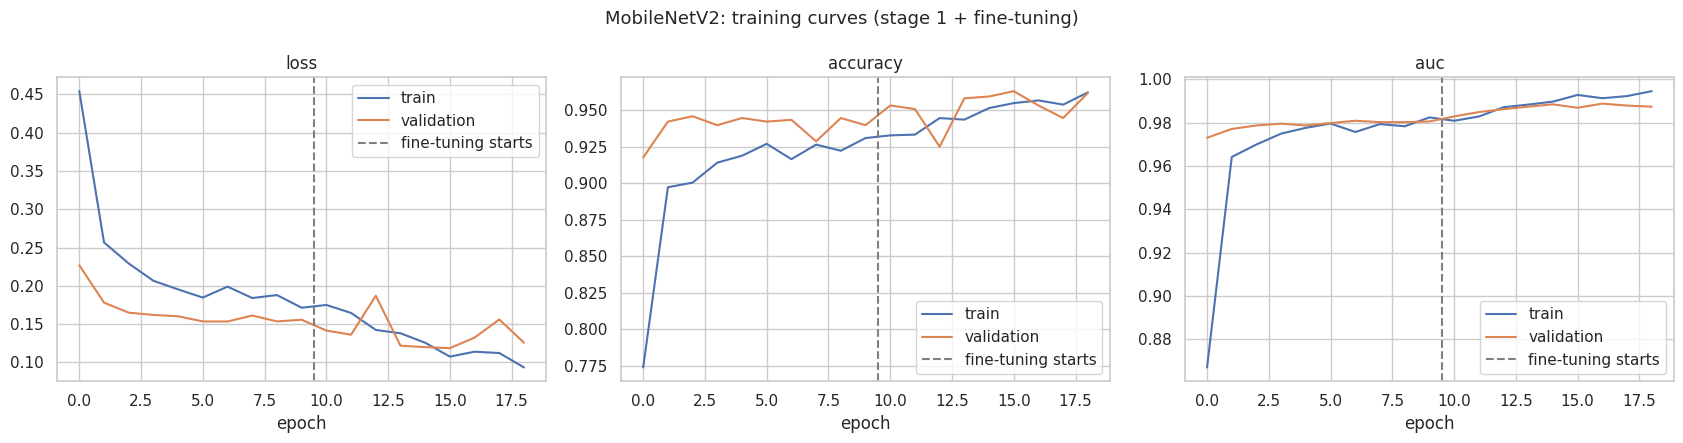

epoch/accuracy,▁▆▆▆▆▇▆▇▇▇▇▇▇▇█████
epoch/auc,▁▆▇▇▇▇▇▇▇▇▇▇███████
epoch/epoch,▁▁▂▂▃▃▃▄▄▅▅▅▆▆▆▇▇██
epoch/learning_rate,███████▃▃▂▁▁▁▁▁▁▁▁▁
epoch/loss,█▄▄▃▃▃▃▃▃▃▃▂▂▂▂▁▁▁▁
epoch/precision,▁▆▆▇▇▇▇▇▇▇▇▇█▇█████
epoch/recall,▁▅▅▆▆▇▆▇▆▇▇▇▇▇█████
epoch/val_accuracy,▁▅▅▄▅▅▅▃▅▄▆▆▂▇▇█▆▅█
epoch/val_auc,▁▃▄▄▄▄▄▄▄▄▅▆▇▇█▇██▇
epoch/val_loss,█▅▄▄▄▃▃▄▃▃▂▂▅▁▁▁▂▃▁
+2,...


In [37]:
set_finetune_policy(mobilenet_model, n_last=30)
mobilenet_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                        loss="binary_crossentropy", metrics=get_metrics())
trainable = sum(int(np.prod(w.shape)) for w in mobilenet_model.trainable_weights)
print(f"Trainable parameters (stage 2): {trainable:,}")

wandb.config.update({"finetune_learning_rate": 1e-5, "finetune_unfrozen_layers": 30})

n_head = len(history_head.history["loss"])          # epochs already done in stage 1
history_ft = mobilenet_model.fit(
    train_aug,
    validation_data=val_ds,
    epochs=n_head + 10,
    initial_epoch=n_head,                             # keeps epoch numbering continuous in the logs
    class_weight=class_weight,
    callbacks=get_callbacks(patience=3) + tracking_callbacks("mobilenetv2"),
)

hist_mobilenet = merge_histories(history_head, history_ft)
plot_history(hist_mobilenet, "MobileNetV2: training curves (stage 1 + fine-tuning)",
             finetune_start=n_head)
wandb.finish()

### Interpretation
Fine-tuning improved the model. After the dashed line, validation loss dropped from about 0.155 at the end of stage 1 to a best of **0.119 at epoch 16**, validation AUC rose from 0.981 to between 0.987 and 0.989, and validation accuracy reached 96.3%. Training stopped at epoch 19 after three epochs without improvement, and the weights from epoch 16 were restored (validation accuracy 96.3%, recall 97.2%, AUC 0.987), so adapting the top layers to X-rays was worthwhile.

Training metrics kept improving to the end (training loss 0.093, training AUC 0.995 at epoch 19), while the validation curves flattened and became noisier (a dip at epoch 13 and a rise in loss at epochs 17 and 18). This is the start of overfitting, which early stopping caught. At the best epoch the gap between training and validation is small (loss 0.108 against 0.119), far smaller and steadier than the baseline's, so MobileNetV2 generalises better.

## 10. Model Evaluation

We evaluate both models properly on **validation** (used to choose between models and to set the decision threshold) and **test** (touched only for final reporting). Choosing the model or threshold using the test set would leak information and make the final numbers optimistic.

### 10.1 Predicted probabilities

We collect the true labels and each model's predicted probability of PNEUMONIA for the validation and test sets. `val_ds` and `test_ds` are not shuffled, so labels and predictions line up image by image. Every metric below is computed from these arrays.

In [38]:
def get_labels(ds):
    return np.concatenate([y.numpy().ravel() for _, y in ds]).astype(int)

def predict_probs(model, ds):
    return model.predict(ds, verbose=0).ravel()

y_val = get_labels(val_ds)
y_test = get_labels(test_ds)

models = {"Baseline CNN": baseline_model, "MobileNetV2": mobilenet_model}
P = {name: {"val": predict_probs(m, val_ds), "test": predict_probs(m, test_ds)}
     for name, m in models.items()}

print("Validation images:", len(y_val), "| Test images:", len(y_test))
print("Test class counts (NORMAL, PNEUMONIA):", np.bincount(y_test))

Validation images: 814 | Test images: 814
Test class counts (NORMAL, PNEUMONIA): [207 607]


### Interpretation
The counts match Section 4.1: 814 validation and 814 test images, with 207 NORMAL and 607 PNEUMONIA in the test set (25.4% and 74.6%). Labels and predictions are aligned, so every metric below is computed on the intended data.

### 10.2 Metrics at the default threshold (0.5)

Metrics reported for each model, with what they mean here (PNEUMONIA is the positive class):

- **Accuracy:** share of all predictions that are right. Misleading with 75% PNEUMONIA.
- **Precision:** of images flagged as pneumonia, how many really are.
- **Recall (sensitivity):** of real pneumonia cases, how many were caught. **Missing a case is the costly error in screening.**
- **Specificity:** of healthy images, how many were correctly called normal.
- **F1:** balance of precision and recall.
- **ROC-AUC:** how well the model ranks pneumonia above normal across all thresholds (1.0 is perfect, 0.5 is random).

In [39]:
def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

rows = []
for name in P:
    for split, y in (("val", y_val), ("test", y_test)):
        rows.append({"model": name, "split": split, **compute_metrics(y, P[name][split])})
results = pd.DataFrame(rows).set_index(["model", "split"])
display(results.round(4))

accuracy  precision  recall  specificity      f1  roc_auc  \
model        split                                                              
Baseline CNN val      0.8563     0.9960  0.8105       0.9903  0.8937   0.9883   
             test     0.8636     0.9901  0.8254       0.9758  0.9003   0.9870   
MobileNetV2  val      0.9631     0.9784  0.9720       0.9372  0.9752   0.9888   
             test     0.9521     0.9781  0.9572       0.9372  0.9675   0.9851   

                     TN  FP   FN   TP  
model        split                     
Baseline CNN val    205   2  115  492  
             test   202   5  106  501  
MobileNetV2  val    194  13   17  590  
             test   194  13   26  581

### Interpretation
**MobileNetV2 is clearly better at the default threshold.** Its F1 is 0.975 on validation and 0.968 on test, against 0.894 and 0.900 for the baseline. ROC-AUC, however, is essentially tied: 0.989 against 0.988 on validation, and on test the baseline is even slightly higher (0.987 against 0.985). Both models therefore rank images about equally well, but the baseline's probabilities are pushed towards NORMAL, so at 0.5 it misses many pneumonia cases.

This shows in recall and specificity. The baseline has very high specificity (97.6% on test) but recall of only 82.5%, missing 106 of 607 pneumonia cases, which is the costly error in screening. MobileNetV2 balances the two: recall 95.7% and specificity 93.7%, with 26 missed cases and 13 false alarms. Validation and test results are close for both models (MobileNetV2 F1 0.975 against 0.968, AUC 0.989 against 0.985), so there is no sign of overfitting to the validation set. Given the size bias found in Section 5.3, AUC values near 0.99 for both models may partly reflect image size and acquisition differences, not only lung disease.

### 10.3 Confusion matrices (test set)

A confusion matrix shows exactly *which* mistakes are made. The row is the true class and the column is the predicted class. **False negatives** (pneumonia predicted as normal) are the most dangerous errors here. **False positives** (normal predicted as pneumonia) lead to unnecessary follow-up.

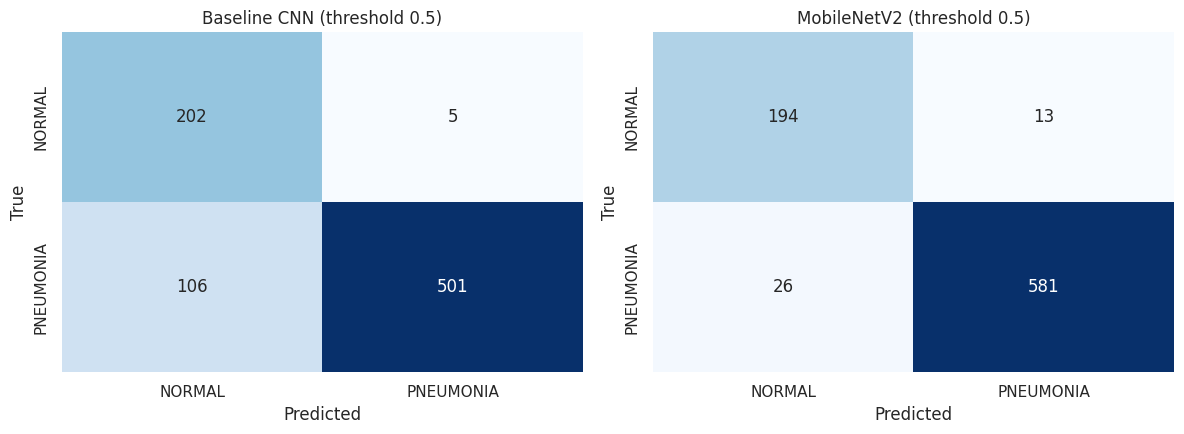

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, P):
    y_pred = (P[name]["test"] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASSES, yticklabels=CLASSES)
    ax.set_title(f"{name} (threshold 0.5)")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

### Interpretation
On the test set at threshold 0.5, the baseline misses **106** pneumonia cases (bottom-left) and raises only **5** false alarms (top-right). MobileNetV2 misses **26** cases and raises **13** false alarms. MobileNetV2 therefore accepts 8 more false alarms in exchange for 80 fewer missed cases, which is the preferred direction for screening, and it makes 39 errors in total against the baseline's 111.

### 10.4 ROC curves (test set)

The ROC curve plots the true-positive rate against the false-positive rate for every possible threshold. The closer a curve hugs the top-left corner, the better; the dashed diagonal is random guessing. The area under it (AUC) summarises the curve in a single number.

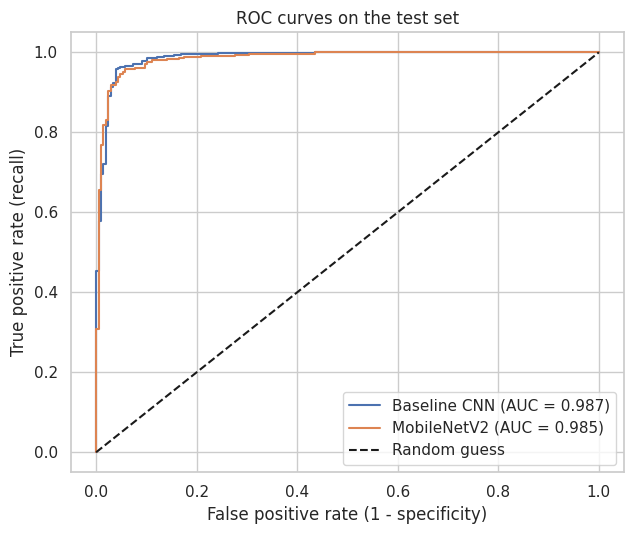

In [42]:
plt.figure(figsize=(6.5, 5.5))
for name in P:
    fpr, tpr, _ = roc_curve(y_test, P[name]["test"])
    auc = roc_auc_score(y_test, P[name]["test"])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate (1 - specificity)")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Interpretation
Both curves hug the top-left corner and are far above the diagonal, so both models have learned to separate the classes. The two curves almost overlap, and the baseline's AUC is marginally higher (0.987 against 0.985), so neither model ranks images meaningfully better. On the left part of the curve, both reach about 95% recall at a false positive rate of about 5%, and close to 99% recall by about 15%, so a strict operating point is achievable with either model.

This means the large gap in Section 10.2 is about where the probabilities sit relative to the threshold, not about ranking ability. The baseline could come closer with its own tuned threshold, but its unstable validation curves (Section 8.4) make it the riskier model to deploy.

### 10.5 Select the best model

The model is chosen using **validation F1** (not test), because it balances catching pneumonia and avoiding false alarms, and because the test set must remain untouched for the final report.

In [43]:
val_table = results.xs("val", level="split")
best_name = val_table["f1"].idxmax()
best_model = models[best_name]
print("Validation F1 per model:")
print(val_table["f1"].round(4).to_string())
print("\nSelected model:", best_name)

Validation F1 per model:
model
Baseline CNN    0.8937
MobileNetV2     0.9752

Selected model: MobileNetV2


### Interpretation
**MobileNetV2 is selected**, with a validation F1 of 0.9752 against 0.8937 for the baseline, a margin of 0.0815 (about 8 points). The margin comes almost entirely from recall (97.2% against 81.1% on validation), since the two models' AUCs are tied. This is the model that is saved, deployed and retrained.

### 10.6 Detailed classification report (selected model, test set)

`classification_report` gives precision, recall and F1 **per class**, plus macro and weighted averages. The macro average treats both classes equally and is therefore more honest than overall accuracy on imbalanced data.

In [44]:
y_pred_best = (P[best_name]["test"] >= 0.5).astype(int)
print(f"Classification report: {best_name} on the test set (threshold 0.5)\n")
print(classification_report(y_test, y_pred_best, target_names=CLASSES, digits=4))

Classification report: MobileNetV2 on the test set (threshold 0.5)

              precision    recall  f1-score   support

      NORMAL     0.8818    0.9372    0.9087       207
   PNEUMONIA     0.9781    0.9572    0.9675       607

    accuracy                         0.9521       814
   macro avg     0.9300    0.9472    0.9381       814
weighted avg     0.9536    0.9521    0.9526       814



### Interpretation
Recall for PNEUMONIA is 0.957 and recall for NORMAL (the specificity) is 0.937, about 2 points lower, as expected for the minority class, but class weighting kept the gap small. The bigger difference is in precision: 0.978 for PNEUMONIA against 0.882 for NORMAL. Of the 220 images predicted NORMAL, 26 were actually pneumonia. Because pneumonia is three times as common, even a small share of missed pneumonia cases makes up a noticeable part of the NORMAL predictions.

The macro-average F1 (0.938) is about 1.5 points below the weighted average (0.953), and the per-class F1 is 0.909 for NORMAL against 0.968 for PNEUMONIA. The minority class is still handled somewhat worse, but the gap is modest.

### 10.7 Choosing the decision threshold

By default an image is called PNEUMONIA when the predicted probability is at least 0.5, but 0.5 is arbitrary. For screening, missing a case is worse than a false alarm, so we choose the threshold **on the validation set** as the one that keeps recall at or above **95%** while giving the best precision possible at that recall. We then apply it to the untouched test set to see the real effect. This threshold is stored with the model and used by the API.

Chosen threshold (from validation data): 0.689


,accuracy,precision,recall,specificity,f1,roc_auc,TN,FP,FN,TP
threshold 0.5,0.9521,0.9781,0.9572,0.9372,0.9675,0.9851,194.0,13.0,26.0,581.0
threshold 0.689,0.9484,0.9813,0.9489,0.9469,0.9648,0.9851,196.0,11.0,31.0,576.0


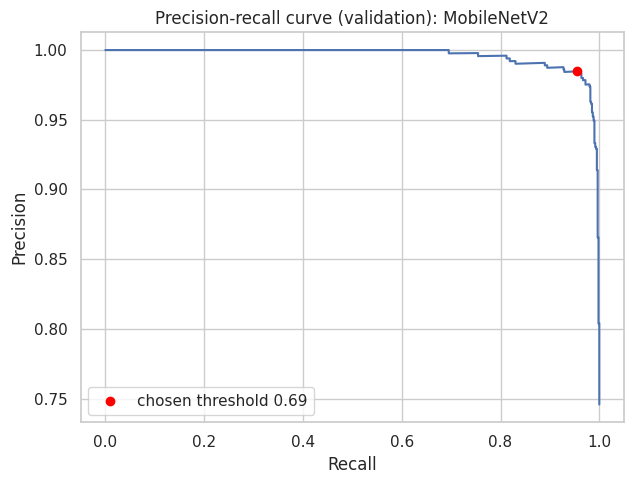

In [45]:
def pick_threshold(y_true, y_prob, min_recall=0.95):
    prec, rec, thr = precision_recall_curve(y_true, y_prob)
    ok = np.where(rec[:-1] >= min_recall)[0]
    if len(ok) == 0:
        return 0.5
    best = ok[np.argmax(prec[:-1][ok])]
    return float(thr[best])

THRESHOLD = pick_threshold(y_val, P[best_name]["val"], min_recall=0.95)
print(f"Chosen threshold (from validation data): {THRESHOLD:.3f}")

compare = pd.DataFrame({
    "threshold 0.5": compute_metrics(y_test, P[best_name]["test"], 0.5),
    f"threshold {THRESHOLD:.3f}": compute_metrics(y_test, P[best_name]["test"], THRESHOLD),
}).T
display(compare.round(4))

prec, rec, thr = precision_recall_curve(y_val, P[best_name]["val"])
plt.figure(figsize=(6.5, 5))
plt.plot(rec, prec)
idx = np.argmin(np.abs(thr - THRESHOLD))
plt.scatter(rec[idx], prec[idx], color="red", zorder=3, label=f"chosen threshold {THRESHOLD:.2f}")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"Precision-recall curve (validation): {best_name}")
plt.legend(); plt.tight_layout(); plt.show()

### Interpretation
The chosen threshold is **0.689, higher than 0.5**. On validation, MobileNetV2 already exceeded the 95% recall target at 0.5 (97.2%), so the rule moved the threshold up to gain precision while keeping validation recall at or above 95%.

On the test set this trades recall for specificity. Recall drops from 95.7% to 94.9% (5 more missed cases, 26 to 31) and specificity rises from 93.7% to 94.7% (2 fewer false alarms, 13 to 11). Precision rises slightly (0.978 to 0.981) and F1 falls slightly (0.968 to 0.965). Test recall of 94.9% is just under the 95% target, so the validation-based choice generalised closely but sits right at the edge: with 607 pneumonia images in the test set, each missed case moves recall by about 0.16 points, and the threshold should be treated as approximate.

For screening, accepting 5 more missed cases to save 2 false alarms is a debatable trade. A stricter target (for example `min_recall=0.97`) or keeping 0.5 would favour fewer missed cases. The operating point is a **design decision for a screening use case, not a clinical standard**, and 0.689 is the value stored with the model and used by the API.

### 10.8 Error analysis: which images does the model get wrong?

Numbers do not show *why* a model fails, so we look at the actual mistakes: the **most confident false negatives** (pneumonia predicted normal) and **most confident false positives** (normal predicted pneumonia). We rebuild an unshuffled test dataset only to get the file paths in the same order as the predictions.

Found 814 files belonging to 2 classes.
False negatives: 31 | False positives: 11


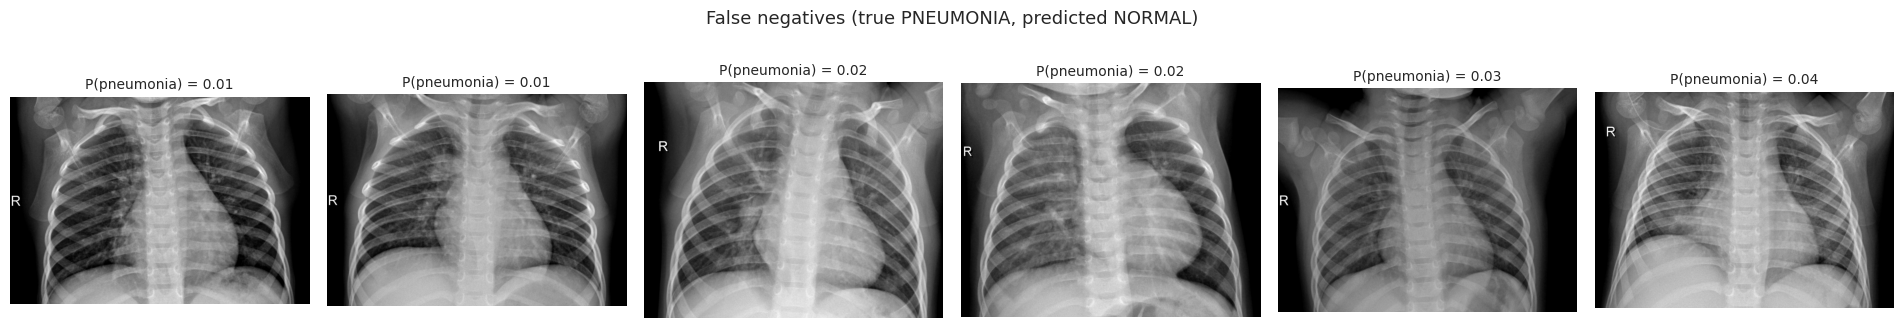

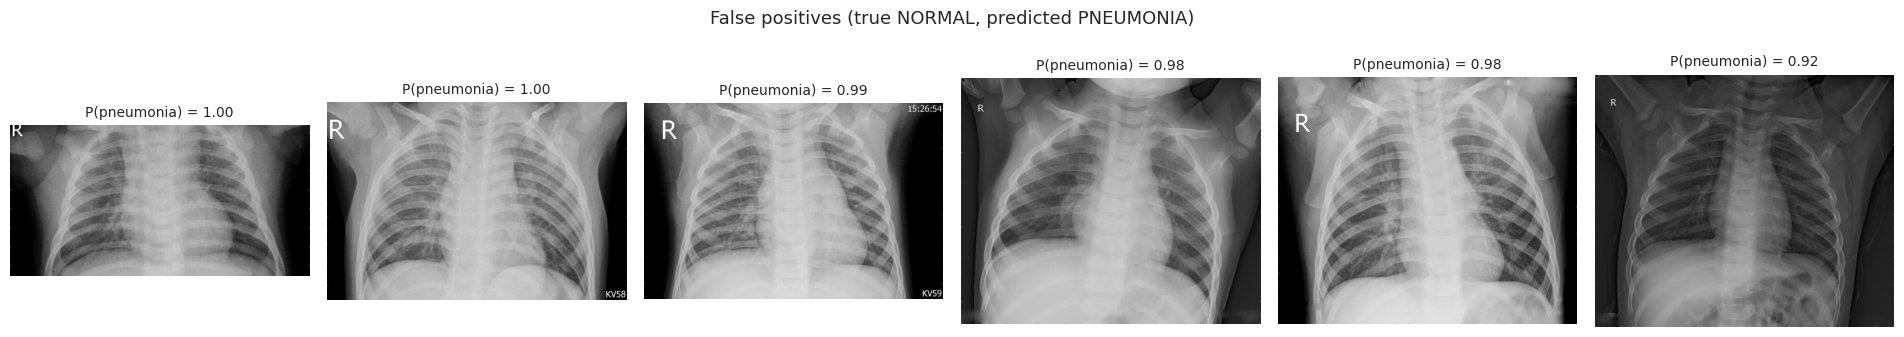

In [47]:
test_raw = tf.keras.utils.image_dataset_from_directory(DATA_DIR / "test", shuffle=False, **common)
test_paths = np.array(test_raw.file_paths)
assert (get_labels(test_raw) == y_test).all(), "Label order mismatch"

prob = P[best_name]["test"]
pred = (prob >= THRESHOLD).astype(int)
fn_idx = np.where((y_test == 1) & (pred == 0))[0]
fp_idx = np.where((y_test == 0) & (pred == 1))[0]
fn_idx = fn_idx[np.argsort(prob[fn_idx])]            # most confidently wrong first
fp_idx = fp_idx[np.argsort(-prob[fp_idx])]
print(f"False negatives: {len(fn_idx)} | False positives: {len(fp_idx)}")

def show_cases(idx, title, n=6):
    idx = idx[:n]
    if len(idx) == 0:
        print(f"No {title.lower()}.")
        return
    fig, axes = plt.subplots(1, len(idx), figsize=(3.2 * len(idx), 3.6))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, idx):
        ax.imshow(Image.open(test_paths[i]).convert("L"), cmap="gray")
        ax.set_title(f"P(pneumonia) = {prob[i]:.2f}", fontsize=10)
        ax.axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

show_cases(fn_idx, "False negatives (true PNEUMONIA, predicted NORMAL)")
show_cases(fp_idx, "False positives (true NORMAL, predicted PNEUMONIA)")

### Interpretation
At threshold 0.689 there are **31 false negatives and 11 false positives**, and the model is very confident on the worst of them.

The **false negatives** (P(pneumonia) between 0.01 and 0.04) have clear, dark lung fields with sharp rib outlines and well-defined heart borders, and look much like the NORMAL samples in Section 5.2. Any opacities are faint and would be hard to see without clinical training. They are also large, wide frames showing the full chest and shoulders, the framing that Section 5.3 found typical of NORMAL images.

The **false positives** (P(pneumonia) between 0.92 and 1.00) show several of the cues seen in PNEUMONIA images during exploration: hazier, lower-contrast lung fields, a small, tightly cropped wide image (the first one), a dark low-contrast scan (the last one), and burned-in text such as kV exposure values and, on one image, a timestamp.

The errors therefore cluster along the size, framing, contrast and text-overlay differences found in Section 5, which suggests the model partly relies on these non-medical cues. The near-0 and near-1 probabilities on wrong cases also show that a confident prediction can still be wrong. This model is a **screening aid only**: both flagged and cleared cases need a clinician's review.

### 10.9 Log the evaluation to Weights & Biases

We record the final evaluation in W&B so it sits next to the training runs: the full metrics table, the selected model and threshold and the test confusion matrix and ROC curve for the selected model.

In [48]:
prob_best = P[best_name]["test"]
pred_best = (prob_best >= THRESHOLD).astype(int)
final = compute_metrics(y_test, prob_best, THRESHOLD)

wb_start("evaluation", tags=["evaluation"], config={"selected_model": best_name, "threshold": THRESHOLD})
wandb.log({
    "results_table": wandb.Table(dataframe=results.reset_index().round(4)),
    "test/confusion_matrix": wandb.plot.confusion_matrix(
        y_true=y_test, preds=pred_best, class_names=CLASSES),
    "test/roc_curve": wandb.plot.roc_curve(
        y_test, np.stack([1 - prob_best, prob_best], axis=1), labels=CLASSES),
})
for k in ("accuracy", "precision", "recall", "specificity", "f1", "roc_auc"):
    wandb.run.summary[f"test_{k}"] = float(final[k])
wandb.finish()
print("Evaluation logged. Test recall at threshold:", round(final["recall"], 4))

test_accuracy,0.9484
test_f1,0.96482
test_precision,0.98126
test_recall,0.94893
test_roc_auc,0.98512
test_specificity,0.94686


Evaluation logged. Test recall at threshold: 0.9489


### Interpretation
The `evaluation` run in the W&B project holds the comparison table, the test confusion matrix and the ROC curve for MobileNetV2. Its summary records the headline test metrics at threshold 0.689: accuracy 0.948, precision 0.981, recall 0.949, specificity 0.947, F1 0.965 and ROC-AUC 0.985. These are the numbers to quote in the report.

## 11. Save the Model and its Metadata

### 11.1 Save

We save the selected model as **`.h5`** (the format the assignment lists) and as **`.keras`** (the current native Keras format, as a safe alternative). Input scaling is inside the model (augmentation is not, see Section 8.1), so the saved file is a self-contained inference model.

A small **metadata JSON** is saved beside it with everything the API needs and nothing it should guess: class order, image size, the decision threshold, the model name and version, and the test metrics. A versioned copy (`pneumonia_model_v1.h5`) is also kept, so a retrained model can be compared with, or rolled back to, the original.

In [49]:
MODEL_PATH = MODELS_DIR / "pneumonia_model.h5"
META_PATH = MODELS_DIR / "model_metadata.json"

best_model.save(MODEL_PATH)
best_model.save(MODELS_DIR / "pneumonia_model.keras")
shutil.copy2(MODEL_PATH, MODELS_DIR / "pneumonia_model_v1.h5")

def save_metadata(meta):
    META_PATH.write_text(json.dumps(meta, indent=2))

def load_metadata():
    return json.loads(META_PATH.read_text())

test_at_thr = compute_metrics(y_test, P[best_name]["test"], THRESHOLD)
metadata = {
    "model_name": best_name,
    "version": 1,
    "classes": CLASSES,
    "img_size": list(IMG_SIZE),
    "threshold": THRESHOLD,
    "trained_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "n_train_images": int(len(full[full["split"] == "train"])),
    "test_metrics": {k: (round(float(v), 4) if isinstance(v, float) else int(v))
                     for k, v in test_at_thr.items()},
}
save_metadata(metadata)

for p in sorted(MODELS_DIR.iterdir()):
    print(f"{p.name:30s} {p.stat().st_size / 1e6:7.2f} MB")
print(json.dumps(metadata, indent=2))

# Register this version as a W&B artifact (versioned model storage)
wb_start("register-model-v1", tags=["model-registry"], config=metadata)
art = wandb.Artifact("pneumonia-model", type="model", metadata=metadata)
art.add_file(str(MODEL_PATH))
art.add_file(str(META_PATH))
wandb.log_artifact(art, aliases=["v1", "deployed"])
wandb.finish()

model_metadata.json               0.00 MB
pneumonia_model.h5               21.51 MB
pneumonia_model.keras            21.73 MB
pneumonia_model_v1.h5            21.51 MB
pneumonia_model_v2.h5            21.51 MB
retrain_log.json                  0.00 MB
{
  "model_name": "MobileNetV2",
  "version": 1,
  "classes": [
    "NORMAL",
    "PNEUMONIA"
  ],
  "img_size": [
    224,
    224
  ],
  "threshold": 0.6888921856880188,
  "trained_at": "2026-11-24T12:11:33",
  "n_train_images": 3796,
  "test_metrics": {
    "accuracy": 0.9484,
    "precision": 0.9813,
    "recall": 0.9489,
    "specificity": 0.9469,
    "f1": 0.9648,
    "roc_auc": 0.9851,
    "TN": 196,
    "FP": 11,
    "FN": 31,
    "TP": 576
  }
}


### Interpretation
The models folder contains `pneumonia_model.h5`, `pneumonia_model.keras`, `pneumonia_model_v1.h5` and `model_metadata.json`, and the metadata records MobileNetV2, version 1, threshold 0.689, 3,796 training images and the test metrics at that threshold. (`pneumonia_model_v2.h5` and `retrain_log.json` also appear because they were left in the working folder by an earlier run; in a fresh session they are created in Section 13.) The Keras warning that `.h5` is a legacy format is expected and harmless.

Each model file is about **21.5 MB**. The MobileNetV2 weights alone are about 9 MB (2.26 million parameters at 4 bytes each); the rest is the Adam optimizer state saved with the model (two extra values for each of the 1.5 million weights trainable during fine-tuning). This is still small enough for fast Docker builds and container start-up.

### 11.2 Reload test

A saved model is only useful if it loads and behaves identically. We reload the `.h5` file in a clean way and confirm that its predictions match the original model's. The difference should be essentially zero.

In [50]:
deployed_model = tf.keras.models.load_model(MODEL_PATH)
reloaded_probs = predict_probs(deployed_model, test_ds)
max_diff = np.abs(reloaded_probs - P[best_name]["test"]).max()
print(f"Largest probability difference after reload: {max_diff:.2e}")
assert max_diff < 1e-3, "Reloaded model does not match the original"
print("Reload check passed.")

Largest probability difference after reload: 0.00e+00
Reload check passed.


### Interpretation
The largest probability difference after reloading is **0.00e+00**: the reloaded `.h5` model gives exactly the same predictions as the model in memory, and the reload check passed. The `.h5` file is safe to use in the API.

## 12. Prediction Function (single image)

### 12.1 Define the function

This is the function the API will call for the **"predict one datapoint"** feature. It takes a file path or raw image bytes (an uploaded file arrives as bytes) and returns the label, the probability and a confidence value.

The image must be preprocessed **exactly as in training**: decoded to 3-channel RGB, resized to 224 x 224 with **bilinear interpolation** using TensorFlow (the same method as `image_dataset_from_directory`), left in 0 to 255 (scaling happens inside the model). Using a different resizer, for example PIL's, would shift pixel values slightly and could lower accuracy in production without any error message, which is why the next cell verifies the match.

In [51]:
PRED_THRESHOLD = load_metadata()["threshold"]

def preprocess_image(image):
    # image: file path (str / Path) or raw bytes
    if isinstance(image, (str, Path)):
        image = Path(image).read_bytes()
    img = tf.io.decode_image(image, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE, method="bilinear")
    return tf.cast(img, tf.float32)

def predict_image(image, model=None, threshold=None):
    model = model or deployed_model
    threshold = PRED_THRESHOLD if threshold is None else threshold
    x = tf.expand_dims(preprocess_image(image), 0)
    p_pneumonia = float(model(x, training=False).numpy()[0][0])
    label = "PNEUMONIA" if p_pneumonia >= threshold else "NORMAL"
    confidence = p_pneumonia if label == "PNEUMONIA" else 1 - p_pneumonia
    return {
        "label": label,
        "probability_pneumonia": round(p_pneumonia, 4),
        "confidence": round(confidence, 4),
        "threshold": round(threshold, 4),
    }

print(predict_image(test_paths[0]))

{'label': 'NORMAL', 'probability_pneumonia': 0.0022, 'confidence': 0.9978, 'threshold': 0.6889}


### Interpretation
For the first test image (a NORMAL X-ray) the function returns `{'label': 'NORMAL', 'probability_pneumonia': 0.0022, 'confidence': 0.9978, 'threshold': 0.6889}`, a correct and confident prediction. This dictionary becomes the JSON the API returns.

### 12.2 Verify it matches the evaluation pipeline

#### Before the cell
We run `predict_image` on 25 random test images and compare its probabilities with the ones from the batch evaluation in Section 10. If preprocessing differs anywhere, the values will not agree. This guards against the most common deployment bug: a model that scores well in the notebook but worse behind the API.

In [52]:
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(test_paths), size=25, replace=False)
single = np.array([predict_image(test_paths[i])["probability_pneumonia"] for i in sample_idx])
batch = P[best_name]["test"][sample_idx]
print("Largest difference (single-image vs batch):", np.abs(single - batch).max())
assert np.abs(single - batch).max() < 5e-3
print("Prediction function matches the evaluation pipeline.")

Largest difference (single-image vs batch): 4.756584167475708e-05
Prediction function matches the evaluation pipeline.


### Interpretation
The largest difference between single-image and batch probabilities across the 25 images is **4.8e-05**, far below the 5e-3 tolerance and at the level of the 4-decimal rounding in `predict_image`. The prediction function is consistent with the evaluation pipeline. These preprocessing steps must stay identical in `src/preprocessing.py` and the API.

### 12.3 Example predictions

A visual demonstration for the demo video: one NORMAL and one PNEUMONIA image from the test set, with the model's output.

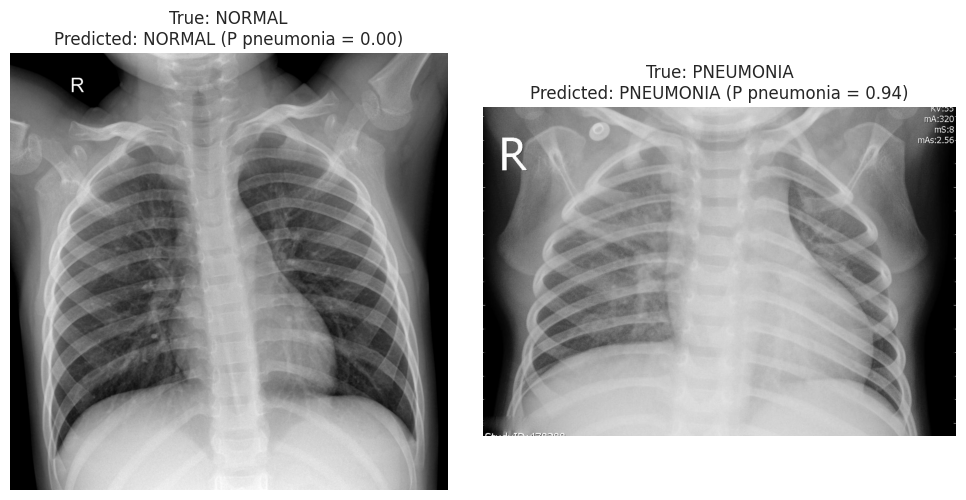

In [54]:
examples = [int(np.where(y_test == 0)[0][0]), int(np.where(y_test == 1)[0][0])]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, i in zip(axes, examples):
    out = predict_image(test_paths[i])
    ax.imshow(Image.open(test_paths[i]).convert("L"), cmap="gray")
    ax.set_title(f"True: {CLASSES[y_test[i]]}\nPredicted: {out['label']} "
                 f"(P pneumonia = {out['probability_pneumonia']:.2f})")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Interpretation
Both examples are classified correctly: the NORMAL X-ray gets P(pneumonia) = 0.00 and the PNEUMONIA X-ray gets 0.94, above the 0.689 threshold. The pneumonia image shows hazier lung fields, and it also carries burned-in exposure text in the top-right corner, the kind of overlay that Section 10.8 linked to errors. Two examples do not prove the model is good; the metrics in Section 10 do. This is a demonstration of how the prediction flow works.

## 13. Model Retraining

Since the model has to be **retrained on newly uploaded data, with a trigger**. We implement three pieces: a **trigger** that decides when retraining is needed, a **retraining function** that continues training the existing model on old plus new data, and a **promotion rule** so a worse model never replaces a better one.

### 13.1 The retraining trigger

Retraining is triggered by either of two conditions:
1. **Enough new data:** at least `RETRAIN_MIN_NEW_IMAGES` (50) newly uploaded images are waiting.
2. **Performance drop:** accuracy measured on recent labelled data falls more than 5 percentage points below the accuracy at deployment time.

The API will call this function after every upload and the UI also offers a manual **Retrain** button that skips the check.

In [56]:
RETRAIN_MIN_NEW_IMAGES = 50
RETRAIN_MAX_ACCURACY_DROP = 0.05

def count_images(folder):
    return sum(1 for p in Path(folder).rglob("*") if p.suffix.lower() in VALID_EXT)

def should_retrain(new_data_dir, live_accuracy=None, baseline_accuracy=None):
    reasons = []
    n_new = count_images(new_data_dir)
    if n_new >= RETRAIN_MIN_NEW_IMAGES:
        reasons.append(f"{n_new} new images uploaded (threshold {RETRAIN_MIN_NEW_IMAGES})")
    if live_accuracy is not None and baseline_accuracy is not None:
        if baseline_accuracy - live_accuracy > RETRAIN_MAX_ACCURACY_DROP:
            reasons.append(f"accuracy fell from {baseline_accuracy:.3f} to {live_accuracy:.3f}")
    return {"retrain": bool(reasons), "n_new_images": n_new, "reasons": reasons}

empty_dir = WORK_DIR / "empty_check"
empty_dir.mkdir(exist_ok=True)
print("No new data:         ", should_retrain(empty_dir))
print("400 new images:      ", should_retrain(DATA_DIR / "new_data"))
print("Accuracy drop only:  ", should_retrain(empty_dir, live_accuracy=0.84, baseline_accuracy=0.93))

No new data:          {'retrain': False, 'n_new_images': 0, 'reasons': []}
400 new images:       {'retrain': True, 'n_new_images': 400, 'reasons': ['400 new images uploaded (threshold 50)']}
Accuracy drop only:   {'retrain': True, 'n_new_images': 0, 'reasons': ['accuracy fell from 0.930 to 0.840']}


### Interpretation
The trigger behaves as intended. With an empty folder it returns `retrain: False`. With the 400 held-out images it returns `True` because 400 is above the threshold of 50, and with no new images but accuracy falling from 0.930 to 0.840 (a 9-point drop, above the 5-point limit) it also returns `True`, with the reason listed. The two conditions work independently. These thresholds are deliberately simple and explainable; in a real service they would be tuned, and the accuracy check would use labelled feedback from clinicians.

### 13.2 The retraining function

`retrain_model` does the following:

1. Loads the **currently deployed** model, so we continue from what it already learned instead of starting over.
2. Combines the original training data with the new data and **recomputes class weights** from the combined counts.
3. Fine-tunes with a **very small learning rate (1e-5)** and a few epochs, so the model adapts without forgetting.
4. Compares old and new on the **same validation set**, and **promotes the new model only if it is not worse**: validation F1 may not drop by more than 1 point and recall may not drop by more than 2 points. Otherwise the old model stays live.
5. Saves a versioned file, updates the metadata and appends to a retraining log.

The API's retrain endpoint will call this same function.

In [61]:
def retrain_model(train_dir, new_data_dir, val_ds, y_val, epochs=5, lr=1e-5,
                  max_f1_drop=0.01, max_recall_drop=0.02):
    meta = load_metadata()
    thr = meta["threshold"]
    old_version = meta["version"]
    model = tf.keras.models.load_model(MODEL_PATH)

    old_val = compute_metrics(y_val, predict_probs(model, val_ds), thr)

    old_ds = tf.keras.utils.image_dataset_from_directory(train_dir, shuffle=True, **common).unbatch()
    new_ds = tf.keras.utils.image_dataset_from_directory(new_data_dir, shuffle=True, **common).unbatch()
    combined = augment_ds(old_ds.concatenate(new_ds).shuffle(2000, seed=SEED)
                          .batch(BATCH_SIZE))

    counts = np.array([count_images(Path(train_dir) / c) + count_images(Path(new_data_dir) / c)
                       for c in CLASSES], dtype=float)
    cw = {i: float(counts.sum() / (2 * counts[i])) for i in range(2)}

    set_finetune_policy(model)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="binary_crossentropy", metrics=get_metrics())
    model.fit(combined, validation_data=val_ds, epochs=epochs, class_weight=cw,
              callbacks=get_callbacks(patience=2), verbose=2)

    new_val = compute_metrics(y_val, predict_probs(model, val_ds), thr)
    promoted = (new_val["f1"] >= old_val["f1"] - max_f1_drop and
                new_val["recall"] >= old_val["recall"] - max_recall_drop)

    new_version = old_version + 1
    candidate_path = MODELS_DIR / f"pneumonia_model_v{new_version}.h5"
    model.save(candidate_path)

    if promoted:
        shutil.copy2(candidate_path, MODEL_PATH)
        meta.update({"version": new_version,
                     "trained_at": datetime.datetime.now().isoformat(timespec="seconds"),
                     "n_train_images": int(counts.sum()),
                     "val_metrics_at_retrain": {k: round(float(v), 4) for k, v in new_val.items()
                                                if k in ("accuracy", "precision", "recall", "f1", "roc_auc")}})
        save_metadata(meta)

    result = {"old_version": old_version, "new_version": new_version, "promoted": bool(promoted),
              "n_train_old": int(sum(count_images(Path(train_dir) / c) for c in CLASSES)),
              "n_new": int(sum(count_images(Path(new_data_dir) / c) for c in CLASSES)),
              "old_val": old_val, "new_val": new_val, "class_weights": cw}

    log_path = MODELS_DIR / "retrain_log.json"
    log = json.loads(log_path.read_text()) if log_path.exists() else []
    log.append({"time": datetime.datetime.now().isoformat(timespec="seconds"),
                "old_version": old_version, "new_version": new_version,
                "promoted": bool(promoted), "n_new": result["n_new"],
                "val_f1_old": round(old_val["f1"], 4), "val_f1_new": round(new_val["f1"], 4)})
    log_path.write_text(json.dumps(log, indent=2))
    return result

print("retrain_model defined.")

retrain_model defined.


### 13.3 Run the retraining flow end to end

This simulates what a user does in the UI: new images are uploaded (here, the 400 held-out images in `data/new_data`, which the model has never seen), the trigger fires and retraining runs. Validation and test sets are unchanged, so the comparison between old and new is fair.

In [62]:
decision = should_retrain(DATA_DIR / "new_data")
print("Trigger decision:", decision)

if decision["retrain"]:
    retrain_result = retrain_model(DATA_DIR / "train", DATA_DIR / "new_data", val_ds, y_val)
    print("\nPromoted new model:", retrain_result["promoted"],
          f"(v{retrain_result['old_version']} -> v{retrain_result['new_version']})")
    print("Training images used:", retrain_result["n_train_old"], "+", retrain_result["n_new"], "new")

    # Record the retraining run in W&B
    wb_start(f"retrain-v{retrain_result['new_version']}", tags=["retraining"], config={
        "trigger_reasons": decision["reasons"], "n_new_images": decision["n_new_images"],
        "promoted": retrain_result["promoted"], "class_weights": retrain_result["class_weights"]})
    wandb.log({f"val_old/{k}": float(v) for k, v in retrain_result["old_val"].items()
               if k in ("accuracy", "precision", "recall", "f1", "roc_auc")})
    wandb.log({f"val_new/{k}": float(v) for k, v in retrain_result["new_val"].items()
               if k in ("accuracy", "precision", "recall", "f1", "roc_auc")})
    cand = MODELS_DIR / f"pneumonia_model_v{retrain_result['new_version']}.h5"
    art = wandb.Artifact("pneumonia-model", type="model", metadata={
        "version": retrain_result["new_version"], "promoted": retrain_result["promoted"]})
    art.add_file(str(cand))
    wandb.log_artifact(art, aliases=[f"v{retrain_result['new_version']}"] +
                       (["deployed"] if retrain_result["promoted"] else []))
    wandb.finish()

Trigger decision: {'retrain': True, 'n_new_images': 400, 'reasons': ['400 new images uploaded (threshold 50)']}


Found 3796 files belonging to 2 classes.
Found 400 files belonging to 2 classes.
Epoch 1/5
132/132 - 55s - 415ms/step - accuracy: 0.9516 - auc: 0.9916 - loss: 0.1142 - precision: 0.9819 - recall: 0.9505 - val_accuracy: 0.9619 - val_auc: 0.9879 - val_loss: 0.1185 - val_precision: 0.9832 - val_recall: 0.9654 - learning_rate: 1.0000e-05
Epoch 2/5
132/132 - 33s - 250ms/step - accuracy: 0.9528 - auc: 0.9916 - loss: 0.1135 - precision: 0.9849 - recall: 0.9492 - val_accuracy: 0.9582 - val_auc: 0.9898 - val_loss: 0.1287 - val_precision: 0.9848 - val_recall: 0.9588 - learning_rate: 1.0000e-05
Epoch 3/5

Epoch 3: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
132/132 - 33s - 250ms/step - accuracy: 0.9597 - auc: 0.9926 - loss: 0.1051 - precision: 0.9848 - recall: 0.9591 - val_accuracy: 0.9263 - val_auc: 0.9875 - val_loss: 0.2027 - val_precision: 0.9893 - val_recall: 0.9110 - learning_rate: 1.0000e-05



Promoted new model: True (v1 -> v2)
Training images used: 3796 + 400 new


val_new/accuracy,▁
val_new/f1,▁
val_new/precision,▁
val_new/recall,▁
val_new/roc_auc,▁
val_old/accuracy,▁
val_old/f1,▁
val_old/precision,▁
val_old/recall,▁
val_old/roc_auc,▁
val_new/accuracy,0.95086


### Interpretation
The trigger fired because 400 new images were waiting. Retraining combined the 3,796 original training images with the 400 new ones (4,196 in total) and recomputed the class weights from the combined counts. Validation loss was best after the first epoch (0.119, with validation accuracy 96.2%, recall 96.5% and AUC 0.988) and then rose (0.129, then 0.203), so early stopping ended the run after epoch 3 and restored the epoch-1 weights.

`Promoted new model: True (v1 -> v2)` means the candidate met the safety rule on the validation set at threshold 0.689 (F1 did not drop by more than 1 point and recall by not more than 2 points). It is now the deployed `pneumonia_model.h5` and the metadata says version 2. The exact old and new validation metrics are stored in `retrain_log.json`. The threshold was not re-tuned, so v2 uses the 0.689 chosen for v1.

### 13.4 Before vs after retraining

We compare the original model (v1) and the retrained candidate (v2) on the **untouched test set**, so the retraining result is judged on data neither model used for learning. We use the same threshold for both so the comparison is like for like.

,accuracy,precision,recall,specificity,f1,roc_auc,FN,FP
v1 (original),0.9484,0.9813,0.9489,0.9469,0.9648,0.9851,31.0,11.0
v2 (retrained),0.9423,0.9828,0.9390,0.9517,0.9604,0.9875,37.0,10.0


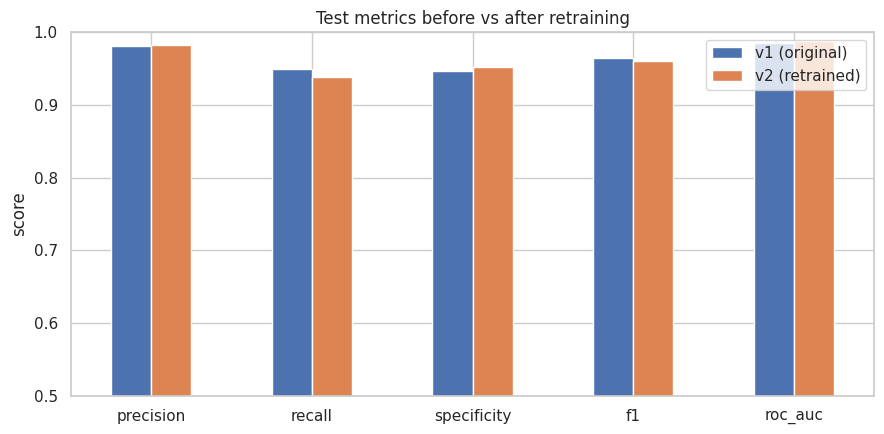

In [63]:
thr = load_metadata()["threshold"]
v1 = tf.keras.models.load_model(MODELS_DIR / "pneumonia_model_v1.h5")
rows = {"v1 (original)": compute_metrics(y_test, predict_probs(v1, test_ds), thr)}

v2_path = MODELS_DIR / "pneumonia_model_v2.h5"
if v2_path.exists():
    v2 = tf.keras.models.load_model(v2_path)
    rows["v2 (retrained)"] = compute_metrics(y_test, predict_probs(v2, test_ds), thr)

cmp_df = pd.DataFrame(rows).T
display(cmp_df[["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "FN", "FP"]].round(4))

cmp_df[["precision", "recall", "specificity", "f1", "roc_auc"]].T.plot(
    kind="bar", figsize=(9, 4.5), rot=0, title="Test metrics before vs after retraining")
plt.ylim(0.5, 1.0)
plt.ylabel("score")
plt.tight_layout()
plt.show()

### Interpretation
On the untouched test set at the same threshold (0.689), the retrained model is **slightly different but not clearly better**:

- **Better:** ROC-AUC rose from 0.985 to 0.988, specificity from 94.7% to 95.2% (false alarms 11 to 10) and precision from 0.981 to 0.983.
- **Worse:** recall fell from 94.9% to 93.9% (missed cases 31 to 37), F1 from 0.965 to 0.960 and accuracy from 94.8% to 94.2%.

All changes are within about 1 point. That is normal: the original model was already trained on thousands of images, and the 400 new images come from the same dataset, so they add little new information. The promotion rule allowed v2 because its validation recall stayed within the 2-point tolerance, but on test the small drop is in the costly direction (more missed cases). Since v2's AUC improved, re-tuning the threshold on validation after each retrain would likely recover the lost recall, and a stricter recall rule would stop this kind of drift. Retraining works end to end and the safeguard runs; its real value would appear with images from a **new hospital or scanner**, where the gain would be larger.

### 13.5 Saved files


In [64]:
print("Models:", sorted(p.name for p in MODELS_DIR.iterdir()))
print("Logs:  ", sorted(p.name for p in LOGS_DIR.iterdir()))

Models: ['model_metadata.json', 'pneumonia_model.h5', 'pneumonia_model.keras', 'pneumonia_model_v1.h5', 'pneumonia_model_v2.h5', 'retrain_log.json']
Logs:   ['baseline_cnn', 'mobilenetv2']


### Interpretation
The models folder contains `pneumonia_model.h5` (now the promoted v2), `pneumonia_model.keras`, the versioned copies `pneumonia_model_v1.h5` and `pneumonia_model_v2.h5`, `model_metadata.json` and `retrain_log.json`, and the logs folder has TensorBoard runs for `baseline_cnn` and `mobilenetv2`. Note that retraining only rewrites the `.h5` file, so `pneumonia_model.keras` still holds v1: the API should load `pneumonia_model.h5`. These files go into the GitHub repo's `models/` folder. At about 21.5 MB each they are below GitHub's 100 MB file limit, so Git LFS is not required.

In [2]:
import zipfile, os
from pathlib import Path

root = Path("/kaggle/working/pneumonia_project")
out = Path("/kaggle/working/pneumonia_project_full.zip")
with zipfile.ZipFile(out, "w", zipfile.ZIP_STORED) as z:
    for p in root.rglob("*"):
        if p.is_file():
            z.write(p, Path("pneumonia_project") / p.relative_to(root))
print(f"{out.name}: {out.stat().st_size / 1e9:.2f} GB")

pneumonia_project_full.zip: 1.32 GB


## 14. Conclusion

### Summary
- **Data:** about 5,800 chest X-rays (Kaggle), cleaned of corrupt files and exact duplicates, re-split 70/15/15 with stratification, and with a balanced 400-image batch held back for retraining.
- **Findings from exploration:** a 3:1 class imbalance, strong differences in image size between the classes, and heavy overlap in brightness. These shaped the choices: class weights, fixed resizing, augmentation, and metrics beyond accuracy.
- **Models:** a baseline CNN versus MobileNetV2 transfer learning, compared using accuracy, precision, recall, specificity, F1, ROC-AUC, confusion matrices and error analysis.
- **Deployment-ready pieces:** a saved `.h5` model with metadata, a prediction function verified against the evaluation pipeline, a retraining trigger, a retraining function with a promotion safeguard, and versioned model files.
- **Headline results:** MobileNetV2 was selected (validation F1 0.975 against 0.894 for the baseline). On the untouched test set at the chosen threshold of 0.689 it reached 94.8% accuracy, 94.9% recall, 94.7% specificity, F1 0.965 and ROC-AUC 0.985, missing 31 of 607 pneumonia cases with 11 false alarms. Retraining on the 400 new images was promoted as v2 (test ROC-AUC 0.988, recall 93.9%).*
